# **1. Business Understanding**

## **1.1. Context**
Olist is a B2C e-commerce platform, wants to optimize the promotion campaign. With the data that the company has related to customer buying and selling behavior. In an effort to reduce expenses and increase campaign effectiveness, the company wants to identify which customer candidates have the potential to become new customers on the Olist platform.

Target:

0 : Not campaign target

1 : Campaign target

## **1.2. Problem Statement**
Olist is currently facing problems in determining which customers are likely to respond to marketing campaigns. Sending promotions to customers who are not likely to engage results in wasted resources, including in marketing budget. To optimize campaign effectiveness, Olist needs to predict which customer segmentation has the potential to make more transactions by being given campaign promotions on the Olist platform.

## **1.3. Goals**
So based on these problems, the company wants to have the ability to predict the likelihood of a customer responding positively to a campaign.
Determine the key factors (e.g., Recency, Frequency, Monetary value) that influence a customer's likelihood to respond to a campaign. Understanding these factors will help Olist to refine it's approach to customer segmentation campaigns more effectively.

## **1.4. Analytical Approach**
What will be done is to analyze data to find customer segmentation patterns using a clusterization model based on purchasing behavior with RFM analysis.
Then a classification model will be built that will help the company's marketing team to be able to predict the probability of customers who have the potential to become regular customers as a target for campaign improvement and those who have no effect.

## **1.5. Evaluation Metrics**
Text

## **1.6. Stakeholder**
Text

# **2. Data Loading**

## **2.1. Import Libraries**

In [1]:
from IPython.core.magic import register_line_magic

@register_line_magic
def silent_pip(line):
    """IPython magic for silent pip installs. Suppresses the output."""
    cmd = f'pip install {line} > /dev/null 2>&1'
    get_ipython().system(cmd)


In [2]:
%silent_pip Levenshtein unidecode


The system cannot find the path specified.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')

from unidecode import unidecode
from Levenshtein import distance as levenshtein_distance

import warnings
warnings.filterwarnings('ignore')


In [4]:
# Display all columns in Pandas DataFrames.
pd.set_option('display.max_columns', None)


## **2.2. Load Datasets**

In [5]:
# Download the "Brazilian E-commerce" dataset from Kaggle.
!kaggle datasets download -d olistbr/brazilian-ecommerce


'kaggle' is not recognized as an internal or external command,
operable program or batch file.


In [6]:
# Extract the contents of the "brazilian-ecommerce.zip" file.
!unzip brazilian-ecommerce.zip


'unzip' is not recognized as an internal or external command,
operable program or batch file.


In [7]:
# Remove the "brazilian-ecommerce.zip" file.
!rm brazilian-ecommerce.zip


'rm' is not recognized as an internal or external command,
operable program or batch file.


In [8]:
# Load the Olist e-commerce dataset into Pandas DataFrames.
customers_df = pd.read_csv('data/olist_customers_dataset.csv')
geolocation_df = pd.read_csv('data/olist_geolocation_dataset.csv')
order_items_df = pd.read_csv('data/olist_order_items_dataset.csv')
order_payments_df = pd.read_csv('data/olist_order_payments_dataset.csv')
order_reviews_df = pd.read_csv('data/olist_order_reviews_dataset.csv')
orders_df = pd.read_csv('data/olist_orders_dataset.csv')
products_df = pd.read_csv('data/olist_products_dataset.csv')
sellers_df = pd.read_csv('data/olist_sellers_dataset.csv')
product_category_df = pd.read_csv('data/product_category_name_translation.csv')


In [9]:
# Create a list of all DataFrames for easier processing.
dfs = [
    customers_df,
    geolocation_df,
    order_items_df,
    order_payments_df,
    order_reviews_df,
    orders_df,
    products_df,
    sellers_df,
    product_category_df
]

# Corresponding list of DataFrame names for informative messages.
df_names = [
    'customers_df',
    'geolocation_df',
    'order_items_df',
    'order_payments_df',
    'order_reviews_df',
    'orders_df',
    'products_df',
    'sellers_df',
    'product_category_df'
]

# Iterate through each DataFrame and handle duplicates.
for i, df in enumerate(dfs):
    num_dups = df.duplicated().sum()

    if num_dups > 0:
        msg = f"Found {num_dups} duplicates in {df_names[i]}. Removing..."
        print(msg)
        df.drop_duplicates(inplace=True)
        df.reset_index(drop=True, inplace=True)
    else:
        print(f"No duplicates found in {df_names[i]}.")


No duplicates found in customers_df.
Found 261831 duplicates in geolocation_df. Removing...
No duplicates found in order_items_df.
No duplicates found in order_payments_df.
No duplicates found in order_reviews_df.
No duplicates found in orders_df.
No duplicates found in products_df.
No duplicates found in sellers_df.
No duplicates found in product_category_df.


In [10]:
# Download the "cities.py" script from GitHub.
# !wget https://raw.githubusercontent.com/cuducos/brazilian-cities/main/cities.py


In [11]:
# Execute the downloaded "cities.py" script.
!python cities.py


python: can't open file 'c:\\Bahasa Planet\\Purwadhika\\Final Project 2\\cities.py': [Errno 2] No such file or directory


In [12]:
# Load the reference cities data into a DataFrame.
ref_cities_df = pd.read_csv('cities.csv')


# **3. Data Cleaning**

In [13]:
def analyze_dataframe(df):
    """
    Analyzes a pandas DataFrame and provides a summary of its features.

    Args:
        df: The pandas DataFrame to analyze.

    Returns:
        None. Displays the first few rows of the DataFrame and a summary table.
    """

    # Initialize a dictionary to store summary statistics for each feature.
    summary_data = {
        'feature': df.columns.values,
        'type': df.dtypes.values,
        'null': df.isna().sum().values,
        'n_unique': df.nunique().values,
        'unique_values': [df[i].unique() for i in df.columns],
        'min_value': pd.Series(dtype='object'),
        'max_value': pd.Series(dtype='object')
    }

    # Create a DataFrame from the summary data.
    summary = pd.DataFrame(summary_data, index=range(len(df.columns)))

    # Identify numeric columns.
    numeric_cols = df.select_dtypes(include='number').columns

    # Calculate and populate min/max values for numeric columns.
    for col in numeric_cols:
        summary.loc[summary['feature'] == col, 'min_value'] = df[col].min()
        summary.loc[summary['feature'] == col, 'max_value'] = df[col].max()

    # Display the first few rows of the DataFrame and the summary table.
    display(df, summary)


## **3.1. customers**

| Columns | Description |
| --- | --- |
| **customer_id** | Unique identifier for each customer. |
| **customer_unique_id** | Unique identifier for each customer (anonymized). |
| **customer_zip_code_prefix** | Zip code prefix of the customer's address. |
| **customer_city** | City where the customer is located. |
| **customer_state** | State where the customer is located. |

In [14]:
# Analyze the 'customers_df' DataFrame before cleaning.
analyze_dataframe(customers_df)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP
...,...,...,...,...,...
99436,17ddf5dd5d51696bb3d7c6291687be6f,1a29b476fee25c95fbafc67c5ac95cf8,3937,sao paulo,SP
99437,e7b71a9017aa05c9a7fd292d714858e8,d52a67c98be1cf6a5c84435bd38d095d,6764,taboao da serra,SP
99438,5e28dfe12db7fb50a4b2f691faecea5e,e9f50caf99f032f0bf3c55141f019d99,60115,fortaleza,CE
99439,56b18e2166679b8a959d72dd06da27f9,73c2643a0a458b49f58cea58833b192e,92120,canoas,RS


,feature,type,null,n_unique,unique_values,min_value,max_value
0,customer_id,object,0,99441,"[06b8999e2fba1a1fbc88172c00ba8bc7, 18955e83d33...",NaN,NaN
1,customer_unique_id,object,0,96096,"[861eff4711a542e4b93843c6dd7febb0, 290c77bc529...",NaN,NaN
2,customer_zip_code_prefix,int64,0,14994,"[14409, 9790, 1151, 8775, 13056, 89254, 4534, ...",1003,99990
3,customer_city,object,0,4119,"[franca, sao bernardo do campo, sao paulo, mog...",NaN,NaN
4,customer_state,object,0,27,"[SP, SC, MG, PR, RJ, RS, PA, GO, ES, BA, MA, M...",NaN,NaN


**Summary**

This dataframe provides customer-related information focusing on their location and identity. It includes:

* **Unique identifiers:** Both a raw `customer_id` and an anonymized `customer_unique_id` are present for tracking individual customers while potentially preserving privacy.
* **Location details:** The `customer_zip_code_prefix`, `customer_city`, and `customer_state` columns offer insights into the geographical distribution of the customer base.

This data can be leveraged for various analyses like understanding customer demographics, regional sales patterns, or optimizing logistics based on customer locations.

**Treatment**

In [15]:
# Rename the 'customer_zip_code_prefix' column to 'zip_code_prefix'.
customers_df.rename(
    columns={'customer_zip_code_prefix': 'zip_code_prefix'},
    inplace=True
)


- The `customer_zip_code_prefix` column was renamed to `zip_code_prefix` to streamline the process of combining this dataset with other dataframes based on zip code prefixes.

In [16]:
# # Drop the 'customer_unique_id' column as it's not needed for analysis.
# customers_df.drop(columns=['customer_unique_id'], inplace=True)


- The `customer_unique_id` column was removed from the `customers_df` dataframe because the `customer_id` column already serves the purpose of uniquely identifying each customer, making `customer_unique_id` redundant.

In [17]:
# Analyze the 'reference_cities_df' DataFrame.
analyze_dataframe(ref_cities_df)


,code,name,state
0,5200050,Abadia de Goiás,GO
1,3100104,Abadia dos Dourados,MG
2,5200100,Abadiânia,GO
3,1500107,Abaetetuba,PA
4,3100203,Abaeté,MG
...,...,...,...
5565,4301552,Áurea,RS
5566,4101150,Ângulo,PR
5567,2900504,Érico Cardoso,BA
5568,1505106,Óbidos,PA


,feature,type,null,n_unique,unique_values,min_value,max_value
0,code,int64,0,5570,"[5200050, 3100104, 5200100, 1500107, 3100203, ...",1100015,5300108
1,name,object,0,5297,"[Abadia de Goiás, Abadia dos Dourados, Abadiân...",NaN,NaN
2,state,object,0,27,"[GO, MG, PA, CE, BA, PR, SC, PE, TO, RN, PI, R...",NaN,NaN


In [18]:
def validate_and_correct_values(df, ref_df, df_col, ref_col):
    """
    Validates values in `df_col` against `ref_col`, and attempts to correct any
    discrepancies.

    Args:
        df: The DataFrame containing the values to be validated.
        ref_df: The reference DataFrame containing the valid values.
        df_col: The name of the column in `df` to validate.
        ref_col: The name of the column in `ref_df` to use for validation.

    Returns:
        None (modifies the original DataFrame `df` in-place).
    """

    # Normalize values for case/diacritic-insensitive comparison.
    normalized_df_values = set(
        df[df_col].astype(str).str.lower().apply(unidecode)
    )
    normalized_ref_df_values = set(
        ref_df[ref_col].astype(str).str.lower().apply(unidecode)
    )

    # Check if all values are present in the reference.
    all_values_present = normalized_df_values.issubset(
        normalized_ref_df_values
    )

    if all_values_present:
        print(f"All values from '{df_col}' are present in '{ref_col}'.")
    else:
        print(f"Some values from '{df_col}' are not present in '{ref_col}'.")
        print("Attempting correction...")

        # Identify incorrect values.
        incorrect_values = normalized_df_values - normalized_ref_df_values

        # Find closest matches for correction using Levenshtein distance.
        value_corrections = {}
        for value in incorrect_values:
            closest_match = min(
                normalized_ref_df_values,
                key=lambda x: levenshtein_distance(x, value),
            )
            value_corrections[value] = closest_match

        # Apply corrections to the original DataFrame.
        df[df_col] = (
            df[df_col]
            .astype(str)
            .str.lower()
            .apply(unidecode)
            .replace(value_corrections)
        )

        print("Correction process completed.")


In [19]:
# Validate and correct city names in 'customers_df'
validate_and_correct_values(
    customers_df, ref_cities_df,
    'customer_city', 'name'
)


Some values from 'customer_city' are not present in 'name'.
Attempting correction...
Correction process completed.


In [20]:
# Validate and correct state names in 'customer_state'
validate_and_correct_values(
    customers_df, ref_cities_df,
    'customer_state', 'state'
)


All values from 'customer_state' are present in 'state'.


- The `validate_and_correct_values` function was applied to ensure data integrity. It successfully:
    - Identified and rectified inconsistencies in the `customer_city` column of the `customers_df` dataframe by cross-referencing it with the `name` column in the `reference_cities_df` dataframe. Discrepancies were resolved using the Levenshtein distance algorithm to pinpoint the closest matching city name.
    - Confirmed that all values within the `customer_state` column of the `customers_df` dataframe were present and accurate when compared against the `state` column in the `reference_cities_df` dataframe.


In [21]:
# Analyze the 'customers_df' DataFrame after cleaning.
analyze_dataframe(customers_df)


,customer_id,customer_unique_id,zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP
...,...,...,...,...,...
99436,17ddf5dd5d51696bb3d7c6291687be6f,1a29b476fee25c95fbafc67c5ac95cf8,3937,sao paulo,SP
99437,e7b71a9017aa05c9a7fd292d714858e8,d52a67c98be1cf6a5c84435bd38d095d,6764,taboao da serra,SP
99438,5e28dfe12db7fb50a4b2f691faecea5e,e9f50caf99f032f0bf3c55141f019d99,60115,fortaleza,CE
99439,56b18e2166679b8a959d72dd06da27f9,73c2643a0a458b49f58cea58833b192e,92120,canoas,RS


,feature,type,null,n_unique,unique_values,min_value,max_value
0,customer_id,object,0,99441,"[06b8999e2fba1a1fbc88172c00ba8bc7, 18955e83d33...",NaN,NaN
1,customer_unique_id,object,0,96096,"[861eff4711a542e4b93843c6dd7febb0, 290c77bc529...",NaN,NaN
2,zip_code_prefix,int64,0,14994,"[14409, 9790, 1151, 8775, 13056, 89254, 4534, ...",1003,99990
3,customer_city,object,0,3937,"[franca, sao bernardo do campo, sao paulo, mog...",NaN,NaN
4,customer_state,object,0,27,"[SP, SC, MG, PR, RJ, RS, PA, GO, ES, BA, MA, M...",NaN,NaN


## **3.2. geolocation**

| Columns | Description |
| --- | --- |
| **geolocation_zip_code_prefix** | Zip code prefix for the location. |
| **geolocation_lat** | Latitude of the location. |
| **geolocation_lng** | Longitude of the location. |
| **geolocation_city** | City of the location. |
| **geolocation_state** | State of the location. |

In [22]:
# Analyze the 'geolocation_df' DataFrame before cleaning.
analyze_dataframe(geolocation_df)


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP
...,...,...,...,...,...
738327,99965,-28.180655,-52.034367,agua santa,RS
738328,99950,-28.072188,-52.011272,tapejara,RS
738329,99950,-28.068864,-52.012964,tapejara,RS
738330,99950,-28.068639,-52.010705,tapejara,RS


,feature,type,null,n_unique,unique_values,min_value,max_value
0,geolocation_zip_code_prefix,int64,0,19015,"[1037, 1046, 1041, 1035, 1012, 1047, 1013, 102...",1001,99990
1,geolocation_lat,float64,0,717360,"[-23.54562128115268, -23.54608112703553, -23.5...",-36.605374,45.065933
2,geolocation_lng,float64,0,717613,"[-46.63929204800168, -46.64482029837157, -46.6...",-101.466766,121.105394
3,geolocation_city,object,0,8011,"[sao paulo, são paulo, sao bernardo do campo, ...",NaN,NaN
4,geolocation_state,object,0,27,"[SP, RN, AC, RJ, ES, MG, BA, SE, PE, AL, PB, C...",NaN,NaN


**Summary**

This dataframe contains geographical data linked to specific locations using zip code prefixes. It includes:

* **Location identifiers:** The `geolocation_zip_code_prefix` serves as the primary key, associating other geographical attributes with specific regions.
* **Spatial coordinates:** Latitude (`geolocation_lat`) and longitude (`geolocation_lng`) provide precise location points, enabling mapping and distance calculations.
* **Administrative details:** The `geolocation_city` and `geolocation_state` offer contextual information about the location's administrative divisions.

This dataset can be utilized for various spatial analyses such as visualizing location distributions, calculating distances between points, or understanding regional trends based on geolocation.

**Treatment**


In [23]:
# Rename the 'geolocation_zip_code_prefix' column to 'zip_code_prefix'.
geolocation_df.rename(
    columns={'geolocation_zip_code_prefix': 'zip_code_prefix'},
    inplace=True
)

- **Renaming:** The column `geolocation_zip_code_prefix` was renamed to `zip_code_prefix` to streamline its usage as a primary key when joining with `customers_df` and `sellers_df`.


In [24]:
# Drop the 'geolocation_city' and 'geolocation_state' columns.
geolocation_df.drop(
    columns=['geolocation_city','geolocation_state'],
    inplace=True
)


- **Dropping redundant columns:** The columns `geolocation_city` and `geolocation_state` were removed to avoid redundancy, as this information is already present in the `customers_df` and `sellers_df` datasets.


In [25]:
# Remove duplicate rows based on 'zip_code_prefix'.
geolocation_df = (
    geolocation_df
    .drop_duplicates(subset=['zip_code_prefix'])
    .reset_index(drop=True)
)


- **Removing duplicates:** Duplicate rows based on the `zip_code_prefix` were eliminated to ensure data integrity and prevent potential issues during subsequent joins or analyses.

In [26]:
# Analyze the 'geolocation_df' DataFrame after cleaning.
analyze_dataframe(geolocation_df)


,zip_code_prefix,geolocation_lat,geolocation_lng
0,1037,-23.545621,-46.639292
1,1046,-23.546081,-46.644820
2,1041,-23.544392,-46.639499
3,1035,-23.541578,-46.641607
4,1012,-23.547762,-46.635361
...,...,...,...
19010,99955,-28.107588,-52.144019
19011,99970,-28.345143,-51.876926
19012,99910,-27.863500,-52.084760
19013,99920,-27.858716,-52.300403


,feature,type,null,n_unique,unique_values,min_value,max_value
0,zip_code_prefix,int64,0,19015,"[1037, 1046, 1041, 1035, 1012, 1047, 1013, 102...",1001,99990
1,geolocation_lat,float64,0,18987,"[-23.54562128115268, -23.54608112703553, -23.5...",-36.605374,42.184003
2,geolocation_lng,float64,0,18988,"[-46.63929204800168, -46.64482029837157, -46.6...",-72.927296,121.105394


## **3.3. order_items**

| Columns | Description |
| --- | --- |
| **order_id** | Unique identifier for the order. |
| **order_item_id** | Unique identifier for each item within an order. |
| **product_id** | Unique identifier for the product being ordered. |
| **seller_id** | Unique identifier for the seller who listed the product. |
| **shipping_limit_date** | Date and time when the seller has to ship the product. |
| **price** | Price of the product. |
| **freight_value** | Shipping fee for the product. |

In [27]:
# Analyze the 'order_items_df' DataFrame before cleaning.
analyze_dataframe(order_items_df)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14
...,...,...,...,...,...,...,...
112645,fffc94f6ce00a00581880bf54a75a037,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:01,299.99,43.41
112646,fffcd46ef2263f404302a634eb57f7eb,1,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:48,350.00,36.53
112647,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95
112648,fffe18544ffabc95dfada21779c9644f,1,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:32,55.99,8.72


,feature,type,null,n_unique,unique_values,min_value,max_value
0,order_id,object,0,98666,"[00010242fe8c5a6d1ba2dd792cb16214, 00018f77f2f...",NaN,NaN
1,order_item_id,int64,0,21,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...",1,21
2,product_id,object,0,32951,"[4244733e06e7ecb4970a6e2683c13e61, e5f2d52b802...",NaN,NaN
3,seller_id,object,0,3095,"[48436dade18ac8b2bce089ec2a041202, dd7ddc04e1b...",NaN,NaN
4,shipping_limit_date,object,0,93318,"[2017-09-19 09:45:35, 2017-05-03 11:05:13, 201...",NaN,NaN
5,price,float64,0,5968,"[58.9, 239.9, 199.0, 12.99, 199.9, 21.9, 19.9,...",0.85,6735.0
6,freight_value,float64,0,6999,"[13.29, 19.93, 17.87, 12.79, 18.14, 12.69, 11....",0.0,409.68


**Summary**

This dataframe captures transactional details of orders, connecting products, sellers, and shipping information. It includes:

* **Order identifiers:** The `order_id` and `order_item_id` provide a hierarchical structure to track individual orders and the items within them.
* **Product and seller links:** The `product_id` and `seller_id` establish relationships between ordered products and the sellers responsible for them.
* **Shipping and pricing:** The `shipping_limit_date` sets the deadline for sellers to dispatch orders, while `price` and `freight_value` detail the product cost and associated shipping fee.

This data can be used for various analyses such as tracking order fulfillment, calculating revenue and shipping costs, or understanding product and seller performance.


**Treatment**


In [28]:
# Convert 'shipping_limit_date' column to datetime.
order_items_df['shipping_limit_date'] = pd.to_datetime(
    order_items_df['shipping_limit_date']
)


- **Converting Date Columns to Datetime:** Specific columns containing date-related information were converted to the datetime data type, enabling time-based operations and analysis.

In [29]:
analyze_dataframe(order_items_df)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14
...,...,...,...,...,...,...,...
112645,fffc94f6ce00a00581880bf54a75a037,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:01,299.99,43.41
112646,fffcd46ef2263f404302a634eb57f7eb,1,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:48,350.00,36.53
112647,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95
112648,fffe18544ffabc95dfada21779c9644f,1,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:32,55.99,8.72


,feature,type,null,n_unique,unique_values,min_value,max_value
0,order_id,object,0,98666,"[00010242fe8c5a6d1ba2dd792cb16214, 00018f77f2f...",NaN,NaN
1,order_item_id,int64,0,21,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...",1,21
2,product_id,object,0,32951,"[4244733e06e7ecb4970a6e2683c13e61, e5f2d52b802...",NaN,NaN
3,seller_id,object,0,3095,"[48436dade18ac8b2bce089ec2a041202, dd7ddc04e1b...",NaN,NaN
4,shipping_limit_date,datetime64[ns],0,93318,"[2017-09-19 09:45:35, 2017-05-03 11:05:13, 201...",NaN,NaN
5,price,float64,0,5968,"[58.9, 239.9, 199.0, 12.99, 199.9, 21.9, 19.9,...",0.85,6735.0
6,freight_value,float64,0,6999,"[13.29, 19.93, 17.87, 12.79, 18.14, 12.69, 11....",0.0,409.68


## **3.4. order_payments**

|Columns|Description|
|---|---|
|**order_id**|Unique identifier for the order.|
|**payment_sequential**|Index number for each payment made for an order.|
|**payment_type**|Type of payment used for the order (e.g., credit card, debit card, voucher).|
|**payment_installments**|Number of installments in which the payment was made.|
|**payment_value**|Value of the payment made.|

In [30]:
# Analyze the 'order_payments_df' DataFrame before cleaning.
analyze_dataframe(order_payments_df)


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45
...,...,...,...,...,...
103881,0406037ad97740d563a178ecc7a2075c,1,boleto,1,363.31
103882,7b905861d7c825891d6347454ea7863f,1,credit_card,2,96.80
103883,32609bbb3dd69b3c066a6860554a77bf,1,credit_card,1,47.77
103884,b8b61059626efa996a60be9bb9320e10,1,credit_card,5,369.54


,feature,type,null,n_unique,unique_values,min_value,max_value
0,order_id,object,0,99440,"[b81ef226f3fe1789b1e8b2acac839d17, a9810da8291...",NaN,NaN
1,payment_sequential,int64,0,29,"[1, 2, 4, 5, 3, 8, 6, 7, 10, 11, 17, 19, 27, 1...",1,29
2,payment_type,object,0,5,"[credit_card, boleto, voucher, debit_card, not...",NaN,NaN
3,payment_installments,int64,0,24,"[8, 1, 2, 3, 6, 5, 4, 10, 7, 12, 9, 13, 15, 24...",0,24
4,payment_value,float64,0,29077,"[99.33, 24.39, 65.71, 107.78, 128.45, 96.12, 8...",0.0,13664.08


**Summary**

This dataframe focuses on the payment aspect of orders, providing details about how customers paid for their purchases. It includes:

* **Order identifier:** The `order_id` links payment information to specific orders in the transactional dataset.
* **Payment sequence:** The `payment_sequential` tracks the order of multiple payments made for a single order, if applicable.
* **Payment method:** The `payment_type` categorizes payments based on the used method, allowing analysis of payment preferences and trends.
* **Installment details:** The `payment_installments` records the number of installments used for payments, revealing insights into customer financing behavior.
* **Payment amount:** The `payment_value` captures the monetary value of each payment made.

This dataset enables exploration of payment patterns, such as preferred payment methods, installment usage, and average payment values, which can be valuable for financial analysis and customer behavior understanding.


**Treatment**

* No specific treatment was performed on this dataframe as all columns are relevant for the subsequent analysis.

## **3.5. order_reviews**

|Columns|Description|
|---|---|
|**review_id**|Unique identifier for each review.|
|**order_id**|Unique identifier for the order that the review is associated with.|
|**review_score**|Numerical score (1-5) given by the customer for the product.|
|**review_comment_title**|Title of the review comment.|
|**review_comment_message**|Text of the review comment.|
|**review_creation_date**|Date and time when the review was created.|
|**review_answer_timestamp**|Date and time when the seller responded to the review (if applicable).|

In [31]:
# Analyze the 'order_reviews_df' DataFrame before cleaning.
analyze_dataframe(order_reviews_df)


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53
...,...,...,...,...,...,...,...
99219,574ed12dd733e5fa530cfd4bbf39d7c9,2a8c23fee101d4d5662fa670396eb8da,5,NaN,NaN,2018-07-07 00:00:00,2018-07-14 17:18:30
99220,f3897127253a9592a73be9bdfdf4ed7a,22ec9f0669f784db00fa86d035cf8602,5,NaN,NaN,2017-12-09 00:00:00,2017-12-11 20:06:42
99221,b3de70c89b1510c4cd3d0649fd302472,55d4004744368f5571d1f590031933e4,5,NaN,"Excelente mochila, entrega super rápida. Super...",2018-03-22 00:00:00,2018-03-23 09:10:43
99222,1adeb9d84d72fe4e337617733eb85149,7725825d039fc1f0ceb7635e3f7d9206,4,NaN,NaN,2018-07-01 00:00:00,2018-07-02 12:59:13


,feature,type,null,n_unique,unique_values,min_value,max_value
0,review_id,object,0,98410,"[7bc2406110b926393aa56f80a40eba40, 80e641a11e5...",NaN,NaN
1,order_id,object,0,98673,"[73fc7af87114b39712e6da79b0a377eb, a548910a1c6...",NaN,NaN
2,review_score,int64,0,5,"[4, 5, 1, 3, 2]",1,5
3,review_comment_title,object,87656,4527,"[nan, recomendo, Super recomendo, Não chegou m...",NaN,NaN
4,review_comment_message,object,58247,36159,"[nan, Recebi bem antes do prazo estipulado., P...",NaN,NaN
5,review_creation_date,object,0,636,"[2018-01-18 00:00:00, 2018-03-10 00:00:00, 201...",NaN,NaN
6,review_answer_timestamp,object,0,98248,"[2018-01-18 21:46:59, 2018-03-11 03:05:13, 201...",NaN,NaN


**Summary**

This dataframe captures customer feedback and seller responses related to orders. It includes:

* **Review identification:** The `review_id` uniquely identifies each review, while the `order_id` links reviews to their corresponding orders.
* **Review content:** The `review_score` quantifies customer satisfaction, and the `review_comment_title` and `review_comment_message` offer qualitative insights into customer experiences.
* **Time stamps:** The `review_creation_date` and `review_answer_timestamp` record when reviews were given and when sellers responded, enabling analysis of response times and review trends over time.

This data can be used for sentiment analysis, understanding customer satisfaction levels, identifying areas for improvement, and evaluating seller responsiveness to feedback.


**Treatment**

In [32]:
# Drop specified columns from 'order_reviews_df'.
order_reviews_df.drop(
    columns=[
        'review_id', 'review_comment_title',
        'review_comment_message', 'review_creation_date',
        'review_answer_timestamp'
    ],
    inplace=True
)


- The columns `review_id`, `review_comment_title`, `review_comment_message`, `review_creation_date`, and `review_answer_timestamp` were dropped from the `order_reviews_df` dataframe. This decision was made because only a subset of the data (40,977 out of 99,224 products) had values in the `review_comment_message` column, making it less representative for comprehensive text analysis. The remaining columns, including `review_score`, were retained for further analysis focused on quantifying customer satisfaction.


In [33]:
# Analyze the 'order_reviews_df' DataFrame after cleaning.
analyze_dataframe(order_reviews_df)


,order_id,review_score
0,73fc7af87114b39712e6da79b0a377eb,4
1,a548910a1c6147796b98fdf73dbeba33,5
2,f9e4b658b201a9f2ecdecbb34bed034b,5
3,658677c97b385a9be170737859d3511b,5
4,8e6bfb81e283fa7e4f11123a3fb894f1,5
...,...,...
99219,2a8c23fee101d4d5662fa670396eb8da,5
99220,22ec9f0669f784db00fa86d035cf8602,5
99221,55d4004744368f5571d1f590031933e4,5
99222,7725825d039fc1f0ceb7635e3f7d9206,4


,feature,type,null,n_unique,unique_values,min_value,max_value
0,order_id,object,0,98673,"[73fc7af87114b39712e6da79b0a377eb, a548910a1c6...",NaN,NaN
1,review_score,int64,0,5,"[4, 5, 1, 3, 2]",1,5


## **3.6. orders**

| Columns | Description |
| --- | --- |
| **order_id** | Unique identifier for each order. |
| **customer_id** | Unique identifier for the customer who placed the order. |
| **order_status** | Current status of the order (e.g., delivered, shipped, canceled). |
| **order_purchase_timestamp** | Date and time when the order was placed. |
| **order_approved_at** | Date and time when the payment for the order was approved. |
| **order_delivered_carrier_date** | Date and time when the order was handed over to the carrier. |
| **order_delivered_customer_date** | Date and time when the order was delivered to the customer. |
| **order_estimated_delivery_date** | Estimated date when the order is expected to be delivered. |

In [34]:
# Analyze the 'orders_df' DataFrame before cleaning.
analyze_dataframe(orders_df)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00
...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00


,feature,type,null,n_unique,unique_values,min_value,max_value
0,order_id,object,0,99441,"[e481f51cbdc54678b7cc49136f2d6af7, 53cdb2fc8bc...",NaN,NaN
1,customer_id,object,0,99441,"[9ef432eb6251297304e76186b10a928d, b0830fb4747...",NaN,NaN
2,order_status,object,0,8,"[delivered, invoiced, shipped, processing, una...",NaN,NaN
3,order_purchase_timestamp,object,0,98875,"[2017-10-02 10:56:33, 2018-07-24 20:41:37, 201...",NaN,NaN
4,order_approved_at,object,160,90733,"[2017-10-02 11:07:15, 2018-07-26 03:24:27, 201...",NaN,NaN
5,order_delivered_carrier_date,object,1783,81018,"[2017-10-04 19:55:00, 2018-07-26 14:31:00, 201...",NaN,NaN
6,order_delivered_customer_date,object,2965,95664,"[2017-10-10 21:25:13, 2018-08-07 15:27:45, 201...",NaN,NaN
7,order_estimated_delivery_date,object,0,459,"[2017-10-18 00:00:00, 2018-08-13 00:00:00, 201...",NaN,NaN


**Summary**

This dataframe tracks the lifecycle of orders, from placement to delivery, including customer associations and status updates. It encompasses:

* **Order identification:** The `order_id` serves as the unique key to identify individual orders.
* **Customer link:** The `customer_id` connects each order to the customer who placed it, enabling customer-centric analysis.
* **Order status and timeline:** The `order_status` provides the current state of the order, while timestamps like `order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, and `order_delivered_customer_date` capture key milestones in the order's journey.
* **Delivery expectation:** The `order_estimated_delivery_date` sets the anticipated delivery timeframe, facilitating comparisons with actual delivery dates.

This dataset is valuable for monitoring order progress, analyzing delivery performance, identifying bottlenecks, and understanding customer behavior in relation to order placement and fulfillment.


**Treatment**

In [35]:
# Count occurrences of each 'order_status'.
orders_df['order_status'].value_counts()


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [36]:
# # Filter 'orders_df' to keep only 'delivered' orders.
# orders_df = orders_df[orders_df['order_status'] == 'delivered']


- **Filtering Delivered Orders:** The dataframe was filtered to keep only the rows where the `order_status` is 'delivered', focusing the analysis on completed orders.


In [37]:
# Drop the 'order_status' column from the 'orders_df' DataFrame.
orders_df.drop(columns=['order_status'], inplace=True)


- **Removing Order Status Column:** The `order_status` column was dropped as it's no longer needed after filtering.


In [38]:
# # Remove rows with missing values.
# orders_df.dropna(inplace=True)
# orders_df.reset_index(drop=True, inplace=True)


- **Handling Missing Values:** Any rows with null values were removed using `dropna()` to ensure data integrity.


In [39]:
# Convert specified columns to datetime format.
date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    orders_df[col] = pd.to_datetime(orders_df[col])


- **Converting Date Columns to Datetime:** Specific columns containing date-related information were converted to the datetime data type, enabling time-based operations and analysis.

In [40]:
# Analyze the 'orders_df' DataFrame after cleaning.
analyze_dataframe(orders_df)


,order_id,customer_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26
...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15


,feature,type,null,n_unique,unique_values,min_value,max_value
0,order_id,object,0,99441,"[e481f51cbdc54678b7cc49136f2d6af7, 53cdb2fc8bc...",NaN,NaN
1,customer_id,object,0,99441,"[9ef432eb6251297304e76186b10a928d, b0830fb4747...",NaN,NaN
2,order_purchase_timestamp,datetime64[ns],0,98875,"[2017-10-02 10:56:33, 2018-07-24 20:41:37, 201...",NaN,NaN
3,order_approved_at,datetime64[ns],160,90733,"[2017-10-02 11:07:15, 2018-07-26 03:24:27, 201...",NaN,NaN
4,order_delivered_carrier_date,datetime64[ns],1783,81018,"[2017-10-04 19:55:00, 2018-07-26 14:31:00, 201...",NaN,NaN
5,order_delivered_customer_date,datetime64[ns],2965,95664,"[2017-10-10 21:25:13, 2018-08-07 15:27:45, 201...",NaN,NaN
6,order_estimated_delivery_date,datetime64[ns],0,459,"[2017-10-18 00:00:00, 2018-08-13 00:00:00, 201...",NaN,NaN


## **3.7. products**

| Columns | Description |
| --- | --- |
| **product_id** | Unique identifier for each product. |
| **product_category_name** | Name of the category that the product belongs to. |
| **product_name_lenght** | Number of characters in the product name. |
| **product_description_lenght** | Number of characters in the product description. |
| **product_photos_qty** | Number of photos for the product. |
| **product_weight_g** | Weight of the product in grams. |
| **product_length_cm** | Length of the product in centimeters. |
| **product_height_cm** | Height of the product in centimeters. |
| **product_width_cm** | Width of the product in centimeters. |

In [41]:
# Analyze the 'products_df' DataFrame before cleaning.
analyze_dataframe(products_df)


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0
...,...,...,...,...,...,...,...,...,...
32946,a0b7d5a992ccda646f2d34e418fff5a0,moveis_decoracao,45.0,67.0,2.0,12300.0,40.0,40.0,40.0
32947,bf4538d88321d0fd4412a93c974510e6,construcao_ferramentas_iluminacao,41.0,971.0,1.0,1700.0,16.0,19.0,16.0
32948,9a7c6041fa9592d9d9ef6cfe62a71f8c,cama_mesa_banho,50.0,799.0,1.0,1400.0,27.0,7.0,27.0
32949,83808703fc0706a22e264b9d75f04a2e,informatica_acessorios,60.0,156.0,2.0,700.0,31.0,13.0,20.0


,feature,type,null,n_unique,unique_values,min_value,max_value
0,product_id,object,0,32951,"[1e9e8ef04dbcff4541ed26657ea517e5, 3aa071139cb...",NaN,NaN
1,product_category_name,object,610,73,"[perfumaria, artes, esporte_lazer, bebes, util...",NaN,NaN
2,product_name_lenght,float64,610,66,"[40.0, 44.0, 46.0, 27.0, 37.0, 60.0, 56.0, 57....",5.0,76.0
3,product_description_lenght,float64,610,2960,"[287.0, 276.0, 250.0, 261.0, 402.0, 745.0, 127...",4.0,3992.0
4,product_photos_qty,float64,610,19,"[1.0, 4.0, 2.0, 3.0, 5.0, 9.0, 6.0, nan, 7.0, ...",1.0,20.0
5,product_weight_g,float64,2,2204,"[225.0, 1000.0, 154.0, 371.0, 625.0, 200.0, 18...",0.0,40425.0
6,product_length_cm,float64,2,99,"[16.0, 30.0, 18.0, 26.0, 20.0, 38.0, 70.0, 40....",7.0,105.0
7,product_height_cm,float64,2,102,"[10.0, 18.0, 9.0, 4.0, 17.0, 5.0, 24.0, 8.0, 1...",2.0,105.0
8,product_width_cm,float64,2,95,"[14.0, 20.0, 15.0, 26.0, 13.0, 11.0, 44.0, 40....",6.0,118.0


**Summary**

This dataframe provides detailed attributes about products, encompassing categorization, textual descriptions, visual representation, and physical dimensions. Key features include:

* **Product identification & categorization:** The `product_id` uniquely identifies each product, while `product_category_name` classifies products into relevant categories for easier organization and analysis.
* **Textual content metrics:** `product_name_lenght` and `product_description_lenght` quantify the extent of product names and descriptions, offering potential insights into information richness and marketing strategies.
* **Visual representation:** The `product_photos_qty` indicates the number of photos associated with each product, reflecting the level of visual detail provided to customers.
* **Physical dimensions:** `product_weight_g`, `product_length_cm`, `product_height_cm`, and `product_width_cm` capture the weight and dimensions of products, aiding in logistics, packaging, and inventory management considerations.

This dataset facilitates various analyses such as understanding product variety across categories, examining the relationship between textual descriptions and sales, assessing the impact of visual content on customer engagement, and optimizing shipping and storage based on product dimensions.


**Treatment**

In [42]:
# Remove rows missing/zero-value.
products_df.dropna(inplace=True)
products_df = products_df[(products_df != 0).all(axis=1)]
products_df.reset_index(drop=True, inplace=True)


- **Data Cleaning:** Rows with null values or any zero values in the dimension columns were dropped to ensure valid calculations and prevent potential division-by-zero errors during subsequent analysis steps.


In [43]:
# Calculate product volume based on dimensions.
products_df['product_volume_cm'] = (
    products_df['product_length_cm'] *
    products_df['product_height_cm'] *
    products_df['product_width_cm']
)


- **Volume Calculation:** A new column, `product_volume_cm`, was calculated by multiplying the `product_length_cm`, `product_height_cm`, and `product_width_cm` columns. This provides a consolidated metric for the overall size of each product.


In [44]:
# Drop individual dimension columns after calculating volume.
products_df.drop(
    columns=[
        'product_length_cm',
        'product_height_cm',
        'product_width_cm'
    ],
    inplace=True
)


- **Dimension Removal:** The original dimension columns (`product_length_cm`, `product_height_cm`, and `product_width_cm`) were dropped after the volume calculation, simplifying the dataframe and focusing on the derived volume metric.


In [45]:
# Analyze the 'products_df' DataFrame after cleaning.
analyze_dataframe(products_df)


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_volume_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,2240.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,10800.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,2430.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,2704.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,4420.0
...,...,...,...,...,...,...,...
32331,a0b7d5a992ccda646f2d34e418fff5a0,moveis_decoracao,45.0,67.0,2.0,12300.0,64000.0
32332,bf4538d88321d0fd4412a93c974510e6,construcao_ferramentas_iluminacao,41.0,971.0,1.0,1700.0,4864.0
32333,9a7c6041fa9592d9d9ef6cfe62a71f8c,cama_mesa_banho,50.0,799.0,1.0,1400.0,5103.0
32334,83808703fc0706a22e264b9d75f04a2e,informatica_acessorios,60.0,156.0,2.0,700.0,8060.0


,feature,type,null,n_unique,unique_values,min_value,max_value
0,product_id,object,0,32336,"[1e9e8ef04dbcff4541ed26657ea517e5, 3aa071139cb...",NaN,NaN
1,product_category_name,object,0,73,"[perfumaria, artes, esporte_lazer, bebes, util...",NaN,NaN
2,product_name_lenght,float64,0,66,"[40.0, 44.0, 46.0, 27.0, 37.0, 60.0, 56.0, 57....",5.0,76.0
3,product_description_lenght,float64,0,2960,"[287.0, 276.0, 250.0, 261.0, 402.0, 745.0, 127...",4.0,3992.0
4,product_photos_qty,float64,0,19,"[1.0, 4.0, 2.0, 3.0, 5.0, 9.0, 6.0, 7.0, 12.0,...",1.0,20.0
5,product_weight_g,float64,0,2201,"[225.0, 1000.0, 154.0, 371.0, 625.0, 200.0, 18...",2.0,40425.0
6,product_volume_cm,float64,0,4487,"[2240.0, 10800.0, 2430.0, 2704.0, 4420.0, 2090...",168.0,296208.0


## **3.8. sellers**

|Columns|Description|
|---|---|
|**seller_id**|Unique identifier for each seller.|
|**seller_zip_code_prefix**|Zip code prefix for the seller's location.|
|**seller_city**|City where the seller is located.|
|**seller_state**|State where the seller is located.|

In [46]:
# Analyze the 'sellers_df' DataFrame before cleaning.
analyze_dataframe(sellers_df)


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP
...,...,...,...,...
3090,98dddbc4601dd4443ca174359b237166,87111,sarandi,PR
3091,f8201cab383e484733266d1906e2fdfa,88137,palhoca,SC
3092,74871d19219c7d518d0090283e03c137,4650,sao paulo,SP
3093,e603cf3fec55f8697c9059638d6c8eb5,96080,pelotas,RS


,feature,type,null,n_unique,unique_values,min_value,max_value
0,seller_id,object,0,3095,"[3442f8959a84dea7ee197c632cb2df15, d1b65fc7deb...",NaN,NaN
1,seller_zip_code_prefix,int64,0,2246,"[13023, 13844, 20031, 4195, 12914, 20920, 5532...",1001,99730
2,seller_city,object,0,611,"[campinas, mogi guacu, rio de janeiro, sao pau...",NaN,NaN
3,seller_state,object,0,23,"[SP, RJ, PE, PR, GO, SC, BA, DF, RS, MG, RN, M...",NaN,NaN


**Summary**

This dataframe provides location-based information about sellers. It includes:

* **Seller identification:** The `seller_id` acts as the unique key to identify individual sellers within the platform.
* **Location details:** The `seller_zip_code_prefix`, `seller_city`, and `seller_state` columns specify the geographical location of each seller.

This data can be used to understand seller distribution, analyze regional sales patterns, or optimize logistics related to seller locations.

**Treatment**

In [47]:
# Rename the 'customer_zip_code_prefix' column to 'zip_code_prefix'.
sellers_df.rename(
    columns={'seller_zip_code_prefix': 'zip_code_prefix'},
    inplace=True
)


- The `seller_zip_code_prefix` column was renamed to `zip_code_prefix`. This change establishes uniformity in column naming and paves the way for effortless merging with other dataframes, notably the `geolocation_df`, which also employ zip code prefixes as a pivotal identifier.


In [48]:
# Validate and correct city names in 'sellers_df'.
validate_and_correct_values(
    sellers_df, ref_cities_df,
    'seller_city', 'name'
)


Some values from 'seller_city' are not present in 'name'.
Attempting correction...
Correction process completed.


In [49]:
# Validate and correct city names in 'sellers_df'.
validate_and_correct_values(
    sellers_df, ref_cities_df,
    'seller_state', 'state'
)


All values from 'seller_state' are present in 'state'.


- The `validate_and_correct_values` function was utilized to uphold data quality. It successfully:
    - Pinpointed and rectified discrepancies within the `seller_city` column of the `sellers_df` dataframe by referencing the `name` column in the `reference_cities_df` dataframe. The Levenshtein distance algorithm was instrumental in resolving inconsistencies by identifying the most closely matching city name.
    - Verified the accuracy and completeness of all values within the `seller_state` column of the `sellers_df` dataframe by comparing them against the `state` column in the `reference_cities_df` dataframe.


In [50]:
# Analyze the 'sellers_df' DataFrame after cleaning.
analyze_dataframe(sellers_df)


,seller_id,zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP
...,...,...,...,...
3090,98dddbc4601dd4443ca174359b237166,87111,sarandi,PR
3091,f8201cab383e484733266d1906e2fdfa,88137,palhoca,SC
3092,74871d19219c7d518d0090283e03c137,4650,sao paulo,SP
3093,e603cf3fec55f8697c9059638d6c8eb5,96080,pelotas,RS


,feature,type,null,n_unique,unique_values,min_value,max_value
0,seller_id,object,0,3095,"[3442f8959a84dea7ee197c632cb2df15, d1b65fc7deb...",NaN,NaN
1,zip_code_prefix,int64,0,2246,"[13023, 13844, 20031, 4195, 12914, 20920, 5532...",1001,99730
2,seller_city,object,0,564,"[campinas, mogi guacu, rio de janeiro, sao pau...",NaN,NaN
3,seller_state,object,0,23,"[SP, RJ, PE, PR, GO, SC, BA, DF, RS, MG, RN, M...",NaN,NaN


## **3.9. product_category**

| Columns | Description |
| --- | --- |
| **product_category_name** | Name of the product category in Portuguese. |
| **product_category_name_english** | Name of the product category in English.
 |

In [51]:
# Analyze the 'product_category_df' DataFrame before cleaning.
analyze_dataframe(product_category_df)


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor
...,...,...
66,flores,flowers
67,artes_e_artesanato,arts_and_craftmanship
68,fraldas_higiene,diapers_and_hygiene
69,fashion_roupa_infanto_juvenil,fashion_childrens_clothes


,feature,type,null,n_unique,unique_values,min_value,max_value
0,product_category_name,object,0,71,"[beleza_saude, informatica_acessorios, automot...",NaN,NaN
1,product_category_name_english,object,0,71,"[health_beauty, computers_accessories, auto, b...",NaN,NaN


**Summary**

This dataframe serves as a translation table, mapping product category names from Portuguese to English. It comprises:

* **Portuguese category:** The `product_category_name` column contains the original product category names in Portuguese.
* **English equivalent:** The `product_category_name_english` column provides the corresponding English translations for each Portuguese category.

This table is essential for standardizing product categorization and enabling analysis or reporting across different language contexts.

**Treatment**

In [52]:
# Extract unique categories from both DataFrames.
product = products_df['product_category_name'].unique()
product_category = product_category_df['product_category_name'].unique()

# Find categories in 'products_df' but not in 'product_category_df'.
missing_categories = set(product) - set(product_category)

if missing_categories:
    print("Missing categories:")
    for category in missing_categories:
        print(category)
else:
    print("All categories present.")


Missing categories:
portateis_cozinha_e_preparadores_de_alimentos
pc_gamer


- **Missing Category Identification:** The code compares the unique product categories in the `products_df` and `product_category_df` dataframes. It identifies and prints any categories present in `products_df` but absent in `product_category_df`, highlighting potential gaps in the translation table.


In [53]:
# New categories to add to 'product_category_df'.
new_categories = [
    {'product_category_name': 'portateis_cozinha_e_preparadores_de_alimentos',
     'product_category_name_english': 'portable_kitchen_food_preparers'},
    {'product_category_name': 'pc_gamer',
     'product_category_name_english': 'pc_gamer'}
]

# Add new categories to the DataFrame.
product_category_df = pd.concat(
    [product_category_df, pd.DataFrame(new_categories)],
    ignore_index=True
)

- **New Category Incorporation:** Two new product categories (`portateis_cozinha_e_preparadores_de_alimentos` and `pc_gamer`) along with their English translations are manually added to the `product_category_df`. This step ensures the translation table remains current and can handle new product categories that may have appeared in the `products_df`.


In [54]:
# Merge 'products_df' with 'product_category_df' to get English category names.
products_df = pd.merge(
    products_df,
    product_category_df,
    on='product_category_name',
    how='left'
)

# Drop the original Portuguese category name column.
products_df.drop('product_category_name', axis=1, inplace=True)

# Rename the English category name column for consistency.
products_df.rename(
    columns={'product_category_name_english': 'product_category_name'},
    inplace=True
)


- **Data Merging and Cleanup:**
    - The `products_df` and `product_category_df` are merged based on the common `product_category_name` column.
    - The original Portuguese `product_category_name` column is removed from `products_df`.
    - The `product_category_name_english` column is renamed to `product_category_name` for consistency.

In [55]:
# Analyze the 'product_category_df' DataFrame after cleaning.
analyze_dataframe(product_category_df)


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor
...,...,...
68,fraldas_higiene,diapers_and_hygiene
69,fashion_roupa_infanto_juvenil,fashion_childrens_clothes
70,seguros_e_servicos,security_and_services
71,portateis_cozinha_e_preparadores_de_alimentos,portable_kitchen_food_preparers


,feature,type,null,n_unique,unique_values,min_value,max_value
0,product_category_name,object,0,73,"[beleza_saude, informatica_acessorios, automot...",NaN,NaN
1,product_category_name_english,object,0,73,"[health_beauty, computers_accessories, auto, b...",NaN,NaN


In [56]:
# Analyze the 'product_df' DataFrame after cleaning.
analyze_dataframe(products_df)


,product_id,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_volume_cm,product_category_name
0,1e9e8ef04dbcff4541ed26657ea517e5,40.0,287.0,1.0,225.0,2240.0,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,44.0,276.0,1.0,1000.0,10800.0,art
2,96bd76ec8810374ed1b65e291975717f,46.0,250.0,1.0,154.0,2430.0,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,27.0,261.0,1.0,371.0,2704.0,baby
4,9dc1a7de274444849c219cff195d0b71,37.0,402.0,4.0,625.0,4420.0,housewares
...,...,...,...,...,...,...,...
32331,a0b7d5a992ccda646f2d34e418fff5a0,45.0,67.0,2.0,12300.0,64000.0,furniture_decor
32332,bf4538d88321d0fd4412a93c974510e6,41.0,971.0,1.0,1700.0,4864.0,construction_tools_lights
32333,9a7c6041fa9592d9d9ef6cfe62a71f8c,50.0,799.0,1.0,1400.0,5103.0,bed_bath_table
32334,83808703fc0706a22e264b9d75f04a2e,60.0,156.0,2.0,700.0,8060.0,computers_accessories


,feature,type,null,n_unique,unique_values,min_value,max_value
0,product_id,object,0,32336,"[1e9e8ef04dbcff4541ed26657ea517e5, 3aa071139cb...",NaN,NaN
1,product_name_lenght,float64,0,66,"[40.0, 44.0, 46.0, 27.0, 37.0, 60.0, 56.0, 57....",5.0,76.0
2,product_description_lenght,float64,0,2960,"[287.0, 276.0, 250.0, 261.0, 402.0, 745.0, 127...",4.0,3992.0
3,product_photos_qty,float64,0,19,"[1.0, 4.0, 2.0, 3.0, 5.0, 9.0, 6.0, 7.0, 12.0,...",1.0,20.0
4,product_weight_g,float64,0,2201,"[225.0, 1000.0, 154.0, 371.0, 625.0, 200.0, 18...",2.0,40425.0
5,product_volume_cm,float64,0,4487,"[2240.0, 10800.0, 2430.0, 2704.0, 4420.0, 2090...",168.0,296208.0
6,product_category_name,object,0,73,"[perfumery, art, sports_leisure, baby, housewa...",NaN,NaN


# **4. Data Understanding**

## **3.1. Merge Datasets**

In [57]:
# Merge customer data with geolocation data based on zip code prefix.
df = pd.merge(customers_df, geolocation_df, on='zip_code_prefix', how='inner')

# # Rename columns to specify they belong to customers.
df.rename(columns={'zip_code_prefix': 'customers_zip_code_prefix'}, inplace=True)
df.rename(columns={'geolocation_lat': 'customers_geolocation_lat'}, inplace=True)
df.rename(columns={'geolocation_lng': 'customers_geolocation_lng'}, inplace=True)

# Merge with order data.
df = pd.merge(df, orders_df, on='customer_id', how='inner')

# Merge with order items data.
df = pd.merge(df, order_items_df, on='order_id', how='inner')

# Merge with order payments data.
df = pd.merge(df, order_payments_df, on='order_id', how='inner')

# Merge with order reviews data.
df = pd.merge(df, order_reviews_df, on='order_id', how='inner')

# Merge with product data.
df = pd.merge(df, products_df, on='product_id', how='inner')

# Merge with seller data.
df = pd.merge(df, sellers_df, on='seller_id', how='inner')

# Merge seller data with geolocation data based on zip code prefix.
df = pd.merge(df, geolocation_df, on='zip_code_prefix', how='inner')

# Rename columns to specify they belong to sellers.
df.rename(columns={'zip_code_prefix': 'sellers_zip_code_prefix'}, inplace=True)
df.rename(columns={'geolocation_lat': 'sellers_geolocation_lat'}, inplace=True)
df.rename(columns={'geolocation_lng': 'sellers_geolocation_lng'}, inplace=True)


In [58]:
# Check for duplicates
df.duplicated().sum()

408

In [59]:
# Drop duplicates
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)


In [60]:
# Analyze the merged DataFrame 'df'
analyze_dataframe(df)


,customer_id,customer_unique_id,customers_zip_code_prefix,customer_city,customer_state,customers_geolocation_lat,customers_geolocation_lng,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,payment_sequential,payment_type,payment_installments,payment_value,review_score,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_volume_cm,product_category_name,sellers_zip_code_prefix,seller_city,seller_state,sellers_geolocation_lat,sellers_geolocation_lng
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,-20.509897,-47.397866,00e7ee1b050b8499577073aeb2a297a1,2017-05-16 15:05:35,2017-05-16 15:22:12,2017-05-23 10:47:57,2017-05-25 10:35:35,2017-06-05,1,a9516a079e37a9c9c36b9b78b10169e8,7c67e1448b00f6e969d365cea6b010ab,2017-05-22 15:22:12,124.99,21.88,1,credit_card,2,146.87,4,41.0,1141.0,1.0,8683.0,107136.0,office_furniture,8577,itaquaquecetuba,SP,-23.482623,-46.37449
1,97ee81fede5757f1ab031e83d1a59f56,452fab1c62b178922fc011b0eb89c1b9,47800,barreiras,BA,-12.147031,-44.996092,a4866dfc455353f48014a2b9a86608a2,2018-01-11 16:47:03,2018-01-11 16:55:38,2018-01-26 13:27:50,2018-02-14 13:09:54,2018-03-01,1,a9516a079e37a9c9c36b9b78b10169e8,7c67e1448b00f6e969d365cea6b010ab,2018-01-25 16:55:38,126.99,43.26,1,boleto,1,340.50,4,41.0,1141.0,1.0,8683.0,107136.0,office_furniture,8577,itaquaquecetuba,SP,-23.482623,-46.37449
2,97ee81fede5757f1ab031e83d1a59f56,452fab1c62b178922fc011b0eb89c1b9,47800,barreiras,BA,-12.147031,-44.996092,a4866dfc455353f48014a2b9a86608a2,2018-01-11 16:47:03,2018-01-11 16:55:38,2018-01-26 13:27:50,2018-02-14 13:09:54,2018-03-01,2,a9516a079e37a9c9c36b9b78b10169e8,7c67e1448b00f6e969d365cea6b010ab,2018-01-25 16:55:38,126.99,43.26,1,boleto,1,340.50,4,41.0,1141.0,1.0,8683.0,107136.0,office_furniture,8577,itaquaquecetuba,SP,-23.482623,-46.37449
3,44e25679aa4d5d2ef5103f6b0174a586,613259d64ba972e49dc25b019b7918c3,6414,barueri,SP,-23.495901,-46.874687,03afb3c10af52ddfa3c33b9881bf43f8,2017-12-07 16:41:50,2017-12-07 16:51:57,2017-12-15 13:04:12,2017-12-18 18:10:28,2018-01-09,1,a9516a079e37a9c9c36b9b78b10169e8,7c67e1448b00f6e969d365cea6b010ab,2017-12-19 16:51:57,112.99,18.51,1,credit_card,2,131.50,4,41.0,1141.0,1.0,8683.0,107136.0,office_furniture,8577,itaquaquecetuba,SP,-23.482623,-46.37449
4,ac318397fb90e64c9a724a3fc61ef587,aaad33c5051196b5e73c7d65b9072e1d,37137,alfenas,MG,-21.407289,-45.940358,3c75044db750a89606612ed286713eb8,2018-03-13 20:11:20,2018-03-13 20:49:24,2018-03-27 16:06:18,2018-04-03 02:42:11,2018-04-19,1,a9516a079e37a9c9c36b9b78b10169e8,7c67e1448b00f6e969d365cea6b010ab,2018-03-27 20:31:01,116.99,57.08,2,voucher,1,100.00,3,41.0,1141.0,1.0,8683.0,107136.0,office_furniture,8577,itaquaquecetuba,SP,-23.482623,-46.37449
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
114640,f48c503766cc6385fe6947e623c20b65,5b2f88631e76ec357578704f3a123737,91791,porto alegre,RS,-30.144365,-51.126372,b13efaac3f8cb7730ba737059abc614b,2017-10-26 11:22:23,2017-10-26 11:37:48,2017-10-31 16:58:06,2017-11-08 22:04:00,2017-11-23,1,b48d3e49914549b781c0b59f819b398e,d4a5e99e0dd915df64ba55a7fbd583fd,2017-11-01 11:35:20,7.45,14.10,1,credit_card,1,107.75,1,24.0,338.0,2.0,1200.0,8000.0,health_beauty,5041,sao paulo,SP,-23.523896,-46.69146
114641,f48c503766cc6385fe6947e623c20b65,5b2f88631e76ec357578704f3a123737,91791,porto alegre,RS,-30.144365,-51.126372,b13efaac3f8cb7730ba737059abc614b,2017-10-26 11:22:23,2017-10-26 11:37:48,2017-10-31 16:58:06,2017-11-08 22:04:00,2017-11-23,2,b48d3e49914549b781c0b59f819b398e,d4a5e99e0dd915df64ba55a7fbd583fd,2017-11-01 11:35:20,7.45,14.10,1,credit_card,1,107.75,1,24.0,338.0,2.0,1200.0,8000.0,health_beauty,5041,sao paulo,SP,-23.523896,-46.69146
114642,f48c503766cc6385fe6947e623c20b65,5b2f88631e76ec357578704f

,feature,type,null,n_unique,unique_values,min_value,max_value
0,customer_id,object,0,96050,"[06b8999e2fba1a1fbc88172c00ba8bc7, 97ee81fede5...",NaN,NaN
1,customer_unique_id,object,0,92952,"[861eff4711a542e4b93843c6dd7febb0, 452fab1c62b...",NaN,NaN
2,customers_zip_code_prefix,int64,0,14747,"[14409, 47800, 6414, 37137, 23585, 28950, 4023...",1003,99980
3,customer_city,object,0,3893,"[franca, barreiras, barueri, alfenas, rio de j...",NaN,NaN
4,customer_state,object,0,27,"[SP, BA, MG, RJ, SC, ES, PA, MT, MS, RS, PR, C...",NaN,NaN
5,customers_geolocation_lat,float64,0,14743,"[-20.509897499999997, -12.147030551377815, -23...",-36.605374,42.184003
6,customers_geolocation_lng,float64,0,14744,"[-47.3978655, -44.99609163741842, -46.87468669...",-72.666706,-8.577855
7,order_id,object,0,96050,"[00e7ee1b050b8499577073aeb2a297a1, a4866dfc455...",NaN,NaN
8,order_purchase_timestamp,datetime64[ns],0,95529,"[2017-05-16 15:05:35, 2018-01-11 16:47:03, 201...",NaN,NaN
9,order_approved_at,datetime64[ns],14,87924,"[2017-05-16 15:22:12, 2018-01-11 16:55:38, 201...",NaN,NaN


In [61]:
# df.to_csv('brazilian-ecommerce.csv', index=False)

## **3.2. Exploratory Data Analysis (EDA)**

In [62]:
def visualize_categorical_column(df, column_name, limit=10):
    """
    Visualizes the value counts of a categorical column in a DataFrame using a bar plot.
    Optionally limits the plot to the top 'limit' categories.

    Args:
        df: The DataFrame containing the categorical column.
        column_name: The name of the categorical column to visualize.
        limit: (Optional) The number of top categories to display. If None, all categories are shown.

    Returns:
        None
    """

    plt.figure(figsize=(10, 6))
    value_counts = df[column_name].value_counts()

    # Apply limit if provided
    if limit:
        value_counts = value_counts.head(limit)

    # Convert index to strings for consistent handling and avoid potential numeric sorting
    value_counts.index = value_counts.index.astype(str)

    sns.barplot(x=value_counts.index, y=value_counts.values)
    plt.xlabel(column_name)
    plt.ylabel('Count')
    plt.title(f'Value Counts of {column_name}' + (f' (Top {limit})' if limit else ''))

    # Truncate x-axis labels if necessary
    plt.xticks(
        range(len(value_counts)),
        [label[:15] + ('...' if len(label) > 15 else '') for label in value_counts.index],
        rotation=45
    )

    # Display the simplified count values on top of each bar
    for i, count in enumerate(value_counts.values):
        simplified_count = f"{count/1000:.1f}k" if count >= 1000 else str(count)
        plt.text(i, count, simplified_count, ha='center', va='bottom')

    plt.tight_layout()
    plt.show()

In [63]:
def visualize_numerical_column(df, column_name, bins=10):
    """
    Visualizes the distribution of a numerical column in a DataFrame using a histogram with labels on the bars.

    Args:
        df: The DataFrame containing the numerical column.
        column_name: The name of the numerical column to visualize.
        bins: (Optional) The number of bins for the histogram or a sequence of bin edges. Defaults to 10.

    Returns:
        None
    """

    plt.figure(figsize=(10, 6))  # Default figsize

    # Handle both integer number of bins and explicit bin edges
    if isinstance(bins, int):
        counts, bin_edges = np.histogram(df[column_name], bins=bins)
    else:  # Assuming bins is a sequence of bin edges
        counts, bin_edges = np.histogram(df[column_name], bins=bins)

    # Calculate bin centers for label placement
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    plt.xlabel(column_name)
    plt.ylabel('Frequency')
    plt.title(f'Distribution of {column_name}')  # Default title

    # Create bars with appropriate widths based on bin edges
    bar_width = bin_edges[1] - bin_edges[0]
    plt.bar(bin_centers, counts, width=bar_width * 0.8, align='center')

    # Add labels to the bars, with conditional formatting
    for count, x in zip(counts, bin_centers):
        if count >= 1e6:  # Millions
            label = f"{count/1e6:.1f}M"
        elif count >= 1e3:  # Thousands
            label = f"{count/1e3:.1f}k"
        else:
            label = str(int(count))
        plt.text(x, count, label, ha='center', va='bottom')

    # Set x-axis ticks at bin edges for accurate representation
    plt.xticks(bin_edges)

    # Add gridlines for better readability
    plt.grid(axis='y', alpha=0.75)

    plt.tight_layout()
    plt.show()

A.	Customers
1.	Categorical
•	customer_city
•	customer_state
2.	Numerical
•	None

B.	Sellers
1.	Categorical
•	customer_city
•	customer_state
2.	Numerical
•	None

C.	Products
1.	Categorical
•	product_photos_qty
•	product_category_name
2.	Numerical
•	product_name_lenght
•	product_description_lenght
•	product_weight_g
•	product_volume_cm

D.	Orders
1.	Categorical
•	customer_city
•	customer_state
•	product_id
•	seller_id
•	payment_sequential
•	payment_type
•	payment_installments
•	review_score
•	product_photos_qty
•	product_category_name
•	seller_city
•	seller_state
2.	Numerical
•	price
•	freight_value
•	payment_value
•	product_name_lenght
•	product_description_lenght
•	product_weight_g
•	product_volume_cm




### **3.2.1. Customers**

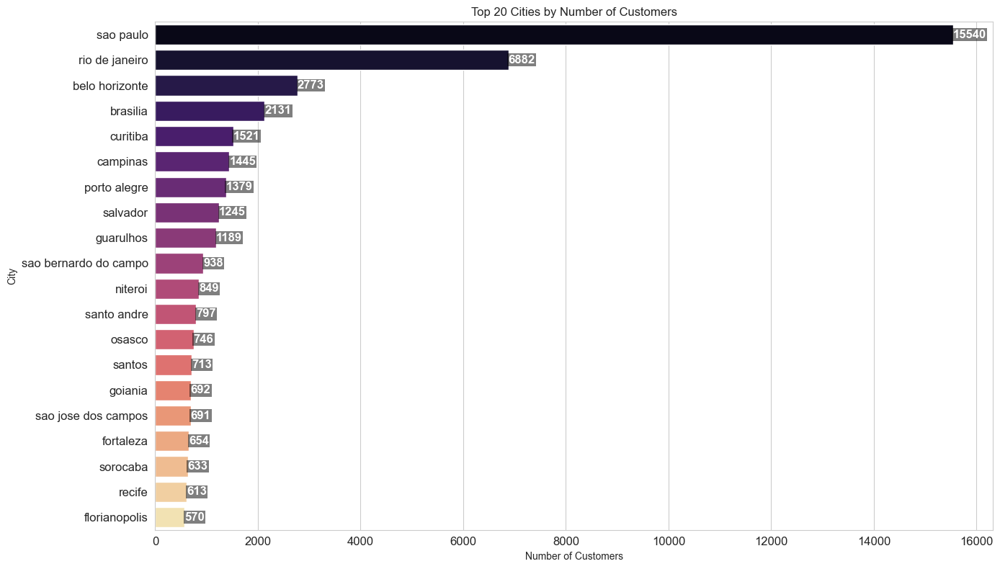

In [64]:
# Group by city and count the number of customers
customers_per_city = customers_df.groupby('customer_city').size().sort_values(ascending=False)

# Select the top 20 cities with the most customers
top_customer_cities = customers_per_city.head(20)

# Plotting
plt.figure(figsize=(14, 8))

ax = sns.barplot(x=top_customer_cities.values, y=top_customer_cities.index, palette='magma')
plt.title('Top 20 Cities by Number of Customers')
plt.xlabel('Number of Customers')
plt.ylabel('City')
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

# Add the numbers inside the bars
for index, value in enumerate(top_customer_cities):
    plt.text(value, index, f'{value}', ha='left', va='center', 
             fontsize=12, color='white', weight='bold', 
             bbox=dict(facecolor='black', alpha=0.5, edgecolor='none', pad=1))

plt.tight_layout()
plt.show()

**Plot Analysis: Top Cities by Number of Customers**

**Top Cities by Number of Customers:**
- **São Paulo** is the leading city with the highest number of customers, reaching nearly 15,000 customers. This significantly surpasses other cities in the list.
- **Rio de Janeiro** follows as the second-largest city by the number of customers, with around 8,882 customers.
- Other notable cities include **Belo Horizonte**, **Brasília**, and **Curitiba**, all of which have over 1,000 customers each.


### **3.2.2. Sellers**

In [65]:
# Extract year and month for grouping
orders_df['year_month'] = orders_df['order_purchase_timestamp'].dt.to_period('M')

# Calculate total sales per month
monthly_sales = orders_df.groupby('year_month').size()

# Extract year for grouping
orders_df['year'] = orders_df['order_purchase_timestamp'].dt.year

# Calculate total sales per year
annual_sales = orders_df.groupby('year').size()


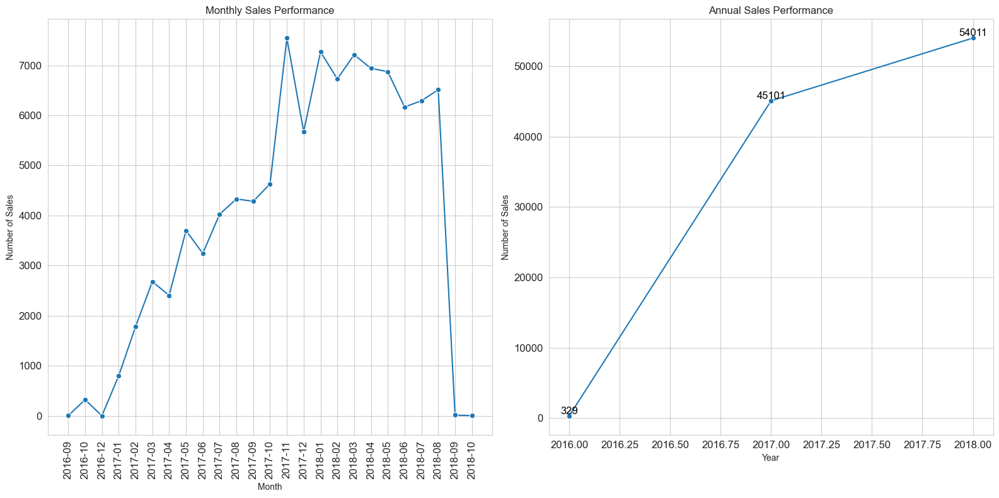

In [66]:
# Plotting
plt.figure(figsize=(16, 8))

# Monthly Sales Plot
plt.subplot(1, 2, 1)
sns.lineplot(x=monthly_sales.index.astype(str), y=monthly_sales.values, marker='o', palette='viridis')
plt.title('Monthly Sales Performance')
plt.xlabel('Month')
plt.ylabel('Number of Sales')
plt.xticks(rotation=90, fontsize=12)
plt.yticks(fontsize=12)

# Annual Sales Plot
plt.subplot(1, 2, 2)
sns.lineplot(x=annual_sales.index, y=annual_sales.values, marker='o', palette='viridis')
plt.title('Annual Sales Performance')
plt.xlabel('Year')
plt.ylabel('Number of Sales')
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

# Add the numbers on the line for annual sales
for x, y in zip(annual_sales.index, annual_sales.values):
    plt.text(x, y, f'{y}', ha='center', va='bottom', fontsize=12, color='black')

plt.tight_layout()
plt.show()

**Plot Analysis and Explanation: Sales Performance**

**Monthly Sales Performance (Left Plot)**
**Trend Overview:**
- The plot illustrates the number of sales each month from September 2016 to October 2018.
- There is a noticeable upward trend from late 2016 through the end of 2017, indicating a period of rapid growth in sales.
- The peak in sales occurred around October 2017, with over 7,000 sales in that month.
- After this peak, there is some fluctuation with a general slight decline in sales through 2018, especially towards the end of the period where sales sharply drop.

**Insights:**
- **2017:** This year marks a period of significant growth, with sales peaking in October and maintaining high levels for several months.
- **2018:** Sales begin to taper off, with a noticeable decline by the middle of the year. The drop towards the end could suggest seasonal factors, market saturation, or other external influences.


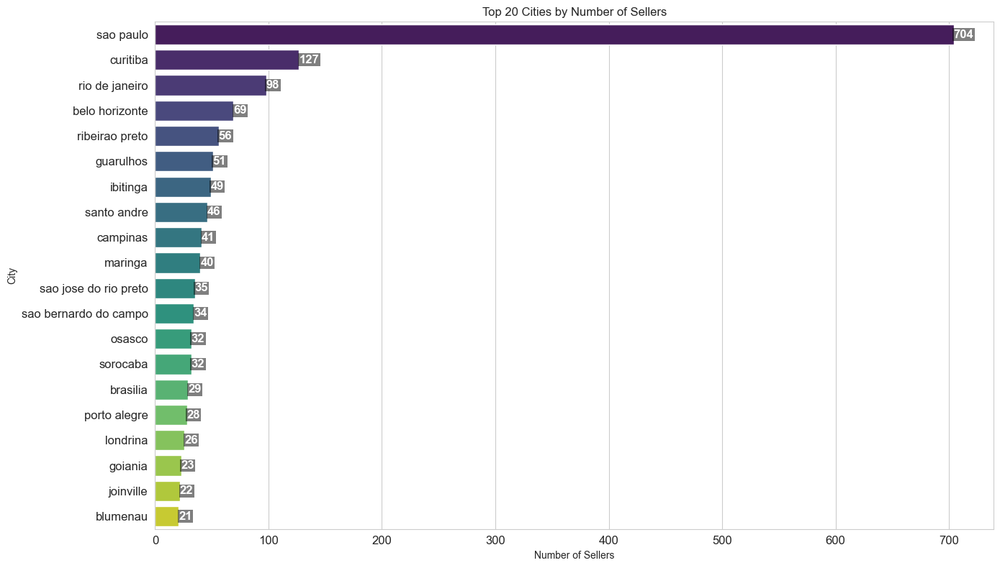

In [67]:
# Group by city and count the number of sellers
sellers_per_city = sellers_df.groupby('seller_city').size().sort_values(ascending=False)

# Select the top 20 cities with the most sellers
top_cities = sellers_per_city.head(20)

# Plotting
plt.figure(figsize=(14, 8))

ax = sns.barplot(x=top_cities.values, y=top_cities.index, palette='viridis')
plt.title('Top 20 Cities by Number of Sellers')
plt.xlabel('Number of Sellers')
plt.ylabel('City')
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

# Add the numbers inside the bars
for index, value in enumerate(top_cities):
    plt.text(value, index, f'{value}', ha='left', va='center', 
             fontsize=12, color='white', weight='bold', 
             bbox=dict(facecolor='black', alpha=0.5, edgecolor='none', pad=1))

plt.tight_layout()
plt.show()


Overall, this graph provides good information on the distribution of sellers across Brazil's main cities, with São Paulo being the most dominant city in terms of the number of sellers.

### **3.2.3. Products**

In [68]:
# Merge datasets
merged = order_items_df.merge(products_df, on='product_id', how='left')

# Calculate revenue for each item
merged['revenue'] = merged['price'] + merged['freight_value']

# Group by product category and calculate total purchases and total revenue
category_summary = merged.groupby('product_category_name')['revenue'].agg(['sum', 'count'])

# Rename columns
category_summary.columns = ['total_revenue', 'total_purchases']

# Sort by total purchases and total revenue
sorted_by_purchases = category_summary.sort_values(by='total_purchases', ascending=False)
sorted_by_revenue = category_summary.sort_values(by='total_revenue', ascending=False)


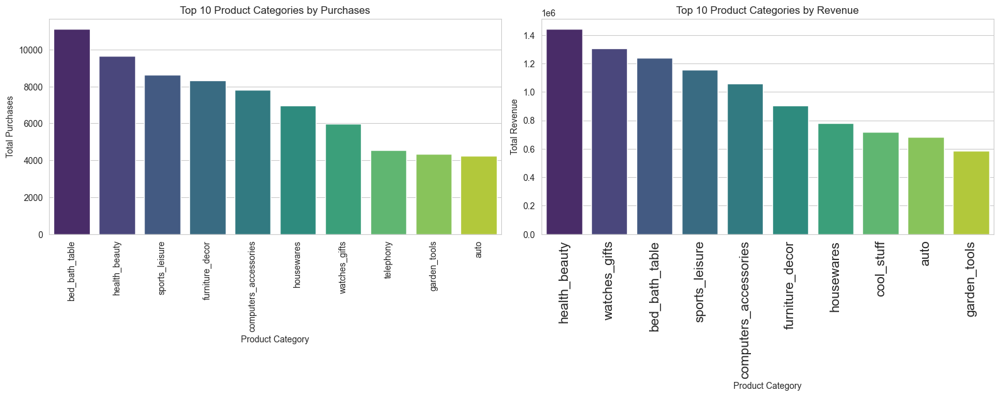

In [69]:
# Get top 10 and lowest 10 categories for purchases and revenue
top_10_purchases = sorted_by_purchases.head(10)
lowest_10_purchases = sorted_by_purchases.tail(10)
top_10_revenue = sorted_by_revenue.head(10)
lowest_10_revenue = sorted_by_revenue.tail(10)
# Plotting
plt.figure(figsize=(16, 10))

# Plot top 10 and lowest 10 categories by purchases
plt.subplot(2, 2, 1)
sns.barplot(x=top_10_purchases.index, y=top_10_purchases['total_purchases'], palette='viridis')
plt.xticks(rotation=90)
plt.title('Top 10 Product Categories by Purchases')
plt.xlabel('Product Category')
plt.ylabel('Total Purchases')

# Plot top 10 and lowest 10 categories by revenue
plt.subplot(2, 2, 2)
sns.barplot(x=top_10_revenue.index, y=top_10_revenue['total_revenue'], palette='viridis')
plt.xticks(rotation=90, fontsize=15)
plt.title('Top 10 Product Categories by Revenue')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')

plt.tight_layout()
plt.show()

From both graphs, it can be seen that the category with the highest number of purchases is not always the category with the highest revenue. For example, “cama_mesa_banho” has the highest number of purchases, but in terms of revenue, “beleza_saude” dominates.
This indicates that some product categories may have a higher price or provide a larger profit margin despite a lower number of purchases.

### **3.2.4. Orders**

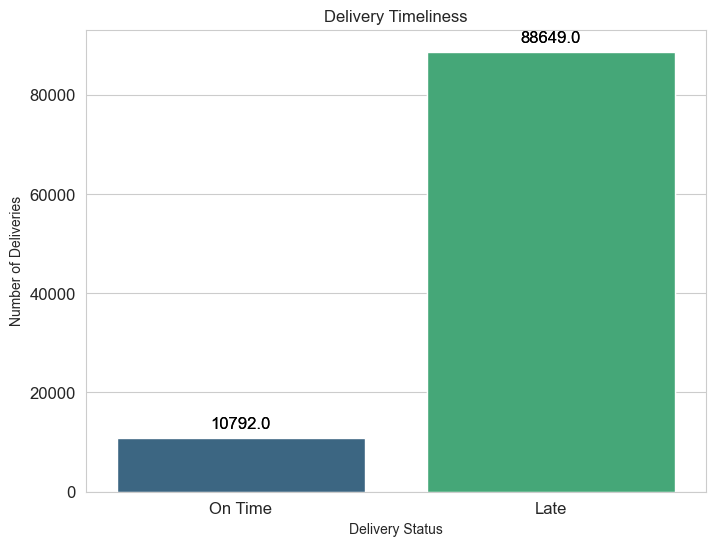

In [70]:
# Determine if delivery is on time
orders_df['on_time'] = orders_df['order_delivered_customer_date'] <= orders_df['order_estimated_delivery_date']

# Count the number of on-time and late deliveries
delivery_status = orders_df['on_time'].value_counts()

# Plotting
plt.figure(figsize=(8, 6))
ax = sns.barplot(x=delivery_status.index, y=delivery_status.values, palette='viridis')
sns.barplot(x=delivery_status.index, y=delivery_status.values, palette='viridis')
plt.title('Delivery Timeliness')
plt.xlabel('Delivery Status')
plt.ylabel('Number of Deliveries')
plt.xticks(ticks=[0, 1], labels=['On Time', 'Late'], fontsize=12)  # Label x-ticks
plt.yticks(fontsize=12)  

# Add the numbers on top of the bars
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 10), 
                textcoords='offset points', 
                fontsize=12, color='black')

plt.show()
plt.show()

The bar chart above shows a comparison of the number of on-time and late deliveries in a marketplace based on the analyzed data. With this data, companies can re-evaluate their delivery processes and look for solutions to reduce delays, such as improving logistics efficiency, working with more couriers, or improving estimated delivery times.

In [71]:
import plotly.express as px
px.pie(order_reviews_df, names='review_score', title='Review Score Distribution')

This figure shows that the majority of customers gave positive reviews (scores of 4 and 5), with only a small percentage giving negative reviews (scores of 1 and 2). This may indicate that in general, the evaluated product or service has a fairly high level of customer satisfaction.

# **5. RFM Analysis**


RFM analysis is a marketing method used to quantitatively rank and categorize customers based on the **Recency**, **Frequency**, and **Monetary** value of their recent transactions. This approach helps in identifying top customers and enables targeted marketing efforts. Each customer is assigned numerical scores for these factors, providing an objective evaluation. This allows businesses to answer questions like _"What types of customers do we have?"_ or _"Who are our top customers?"_ But first, let's clarify what these factors mean:

- **Recency:** Measures how much time has passed since a customer's last purchase. This is crucial because customers who have recently engaged with a brand are more likely to respond to new marketing efforts, making their identification highly valuable.
- **Frequency:** Refers to how often a customer makes a purchase. Customers who buy more frequently are generally more likely to make future purchases.
- **Monetary:** Indicates the total amount a customer has spent over a specific period. High-spending customers are likely to continue spending and hold significant value for the business.

To carry out this analysis, the first step is to define these three parameters.


In [72]:
aggregated_payments = order_payments_df.groupby('order_id', as_index=False).agg({
    'payment_value': 'sum',
    'payment_installments': 'sum',
    'payment_type': lambda x: ', '.join(set(x)),
    'payment_sequential': 'max'
})

In [73]:
merge_df = orders_df.merge(customers_df, on='customer_id', how='inner')

In [74]:
merge_df = aggregated_payments.merge(merge_df, on='order_id', how='inner')

To overcome the problem where one order has multiple payment records (payment_sequential more than 1), we need to aggregate the payment data before merging it with other datasets.

In [75]:
# Recency
latest_date = merge_df['order_purchase_timestamp'].max()
recency = merge_df.groupby('customer_unique_id')['order_purchase_timestamp'].max().reset_index()
recency['Recency'] = (latest_date - recency['order_purchase_timestamp']).dt.days
recency = recency[['customer_unique_id', 'Recency']]
recency

,customer_unique_id,Recency
0,0000366f3b9a7992bf8c76cfdf3221e2,160
1,0000b849f77a49e4a4ce2b2a4ca5be3f,163
2,0000f46a3911fa3c0805444483337064,585
3,0000f6ccb0745a6a4b88665a16c9f078,369
4,0004aac84e0df4da2b147fca70cf8255,336
...,...,...
96090,fffcf5a5ff07b0908bd4e2dbc735a684,495
96091,fffea47cd6d3cc0a88bd621562a9d061,310
96092,ffff371b4d645b6ecea244b27531430a,617
96093,ffff5962728ec6157033ef9805bacc48,168


In [76]:
# Frequency
frequency = merge_df.groupby("customer_unique_id")['order_id'].nunique().reset_index()
frequency.rename(columns={"order_id":"Frequency"}, inplace=True)
frequency

,customer_unique_id,Frequency
0,0000366f3b9a7992bf8c76cfdf3221e2,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1
2,0000f46a3911fa3c0805444483337064,1
3,0000f6ccb0745a6a4b88665a16c9f078,1
4,0004aac84e0df4da2b147fca70cf8255,1
...,...,...
96090,fffcf5a5ff07b0908bd4e2dbc735a684,1
96091,fffea47cd6d3cc0a88bd621562a9d061,1
96092,ffff371b4d645b6ecea244b27531430a,1
96093,ffff5962728ec6157033ef9805bacc48,1


In [77]:
# Monetary
monetary = merge_df.groupby('customer_unique_id')['payment_value'].sum().reset_index()
monetary.rename(columns={"payment_value":"Monetary"}, inplace=True)
monetary

,customer_unique_id,Monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,27.19
2,0000f46a3911fa3c0805444483337064,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,43.62
4,0004aac84e0df4da2b147fca70cf8255,196.89
...,...,...
96090,fffcf5a5ff07b0908bd4e2dbc735a684,2067.42
96091,fffea47cd6d3cc0a88bd621562a9d061,84.58
96092,ffff371b4d645b6ecea244b27531430a,112.46
96093,ffff5962728ec6157033ef9805bacc48,133.69


#### combine RFM value

In [78]:
# Gabungkan RFM
rfm_df = recency.merge(frequency, on='customer_unique_id').merge(monetary, on='customer_unique_id')
rfm_df

,customer_unique_id,Recency,Frequency,Monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,160,1,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,163,1,27.19
2,0000f46a3911fa3c0805444483337064,585,1,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,369,1,43.62
4,0004aac84e0df4da2b147fca70cf8255,336,1,196.89
...,...,...,...,...
96090,fffcf5a5ff07b0908bd4e2dbc735a684,495,1,2067.42
96091,fffea47cd6d3cc0a88bd621562a9d061,310,1,84.58
96092,ffff371b4d645b6ecea244b27531430a,617,1,112.46
96093,ffff5962728ec6157033ef9805bacc48,168,1,133.69


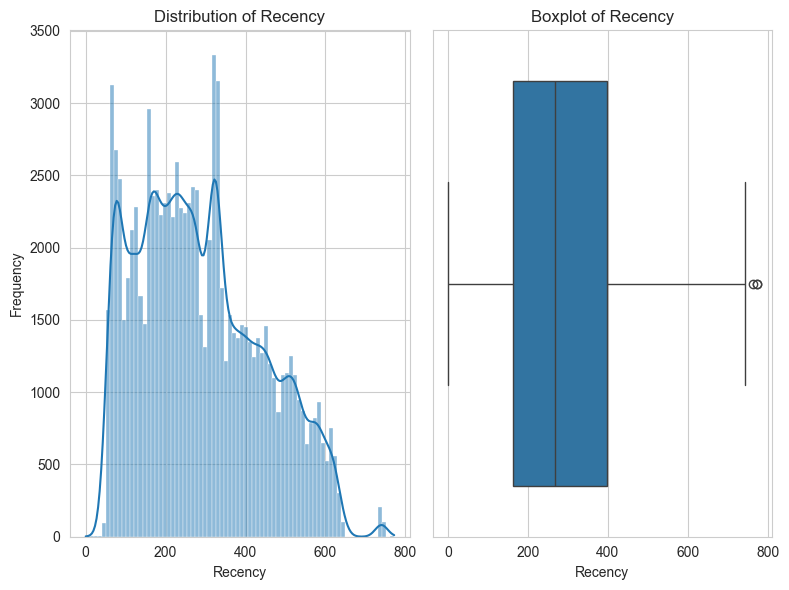

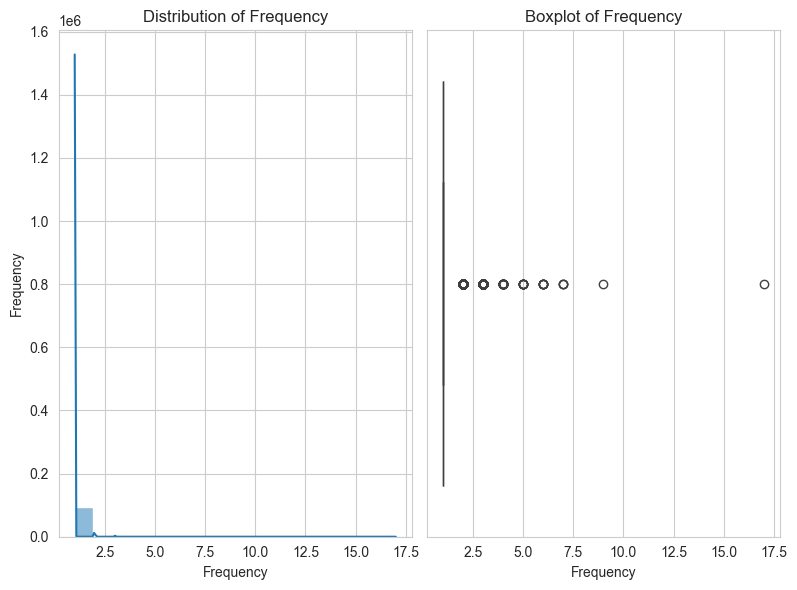

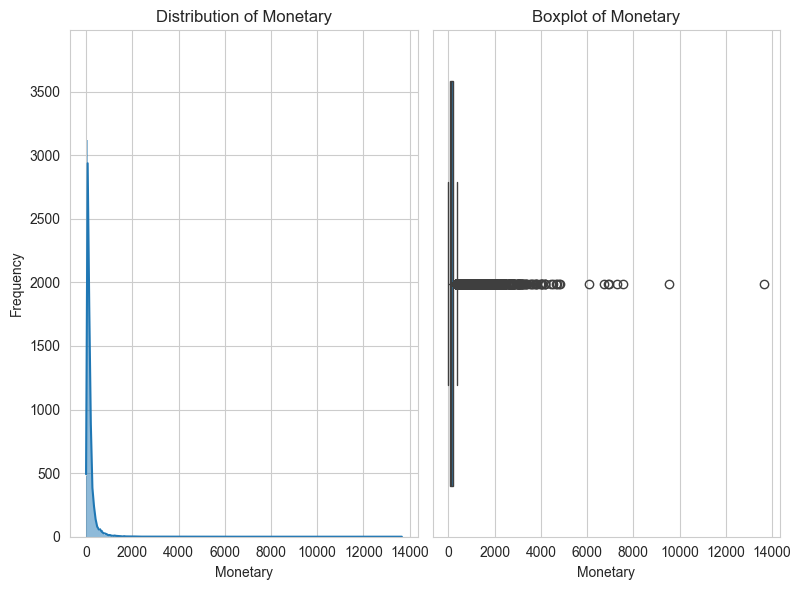

In [82]:
# Select a numeric column from an rfm DataFrame
numerical_cols = rfm_df.select_dtypes(include=['int64', 'float64']).columns

# Distribution plot and boxplot for each numerical column
for col in numerical_cols:
    plt.figure(figsize=(8, 6))
    
    # Histogram
    plt.subplot(1, 2, 1)
    sns.histplot(rfm_df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    
    # Boxplot
    plt.subplot(1, 2, 2)
    sns.boxplot(x=rfm_df[col])
    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)
    
    plt.tight_layout()  
    plt.show()

##### check duplicated

In [83]:
rfm_df.duplicated().sum()

0

##### Scalling

In [84]:
# Normalize the RFM data
from sklearn.preprocessing import RobustScaler, StandardScaler, MinMaxScaler
scaler = RobustScaler()
rfm_scaled_df = rfm_df.copy()
rfm_scaled_df = scaler.fit_transform(rfm_df[['Recency', 'Frequency', 'Monetary']])
rfm_scaled_df = pd.DataFrame(rfm_scaled_df, columns=['Recency', 'Frequency', 'Monetary'])

rfm_scaled_df.head()

,Recency,Frequency,Monetary
0,-0.461538,0.0,0.281538
1,-0.448718,0.0,-0.671124
2,1.354701,0.0,-0.180882
3,0.431624,0.0,-0.534673
4,0.290598,0.0,0.738228


## Elbow method 

Elbow method to define number of cluster

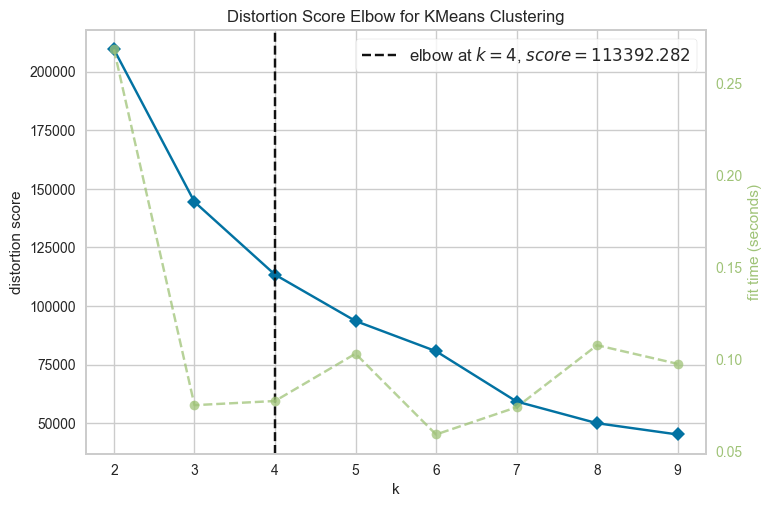

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [85]:
from sklearn.cluster import KMeans
from yellowbrick.cluster import KElbowVisualizer
k_means = KMeans(random_state=0)
elbow = KElbowVisualizer(k_means, k=(2, 10))
elbow.fit(rfm_scaled_df)
elbow.show()

Optimal K =4

In [86]:
# using optimal K to perform clustering wuth rfm data
kmeans = KMeans(n_clusters=4, random_state=0)
rfm_df['cluster'] = kmeans.fit_predict(rfm_df[['Recency','Frequency', 'Monetary']])

In [87]:
# Analyze the clusters
cluster_analysis = rfm_df.groupby('cluster', as_index=False)[['Recency', 'Frequency', 'Monetary']].mean()

# Display the cluster analysis
cluster_analysis

,cluster,Recency,Frequency,Monetary
0,0,177.595251,1.029558,121.306529
1,1,279.396654,1.134514,621.468724
2,2,438.921049,1.024854,121.356992
3,3,287.869263,1.089013,1930.797344


In [88]:
# Count the number of customers in each cluster
cluster_counts = rfm_df.groupby('cluster')['customer_unique_id'].size().reset_index(name='customer_count')

# Merge the counts with the cluster analysis
cluster_analysis = cluster_analysis.merge(cluster_counts, on='cluster')
cluster_analysis

,cluster,Recency,Frequency,Monetary,customer_count
0,0,177.595251,1.029558,121.306529,51459
1,1,279.396654,1.134514,621.468724,6096
2,2,438.921049,1.024854,121.356992,37821
3,3,287.869263,1.089013,1930.797344,719


In [89]:
cluster_analysis

,cluster,Recency,Frequency,Monetary,customer_count
0,0,177.595251,1.029558,121.306529,51459
1,1,279.396654,1.134514,621.468724,6096
2,2,438.921049,1.024854,121.356992,37821
3,3,287.869263,1.089013,1930.797344,719


**Join RFM to customer table**

In [90]:
new_customer_df = pd.merge(customers_df, rfm_df, on='customer_unique_id', how='inner')
new_customer_df = pd.DataFrame(new_customer_df)

In [94]:
# new_customer_df.to_csv('new_customer_df.csv', index=False)

<hr>

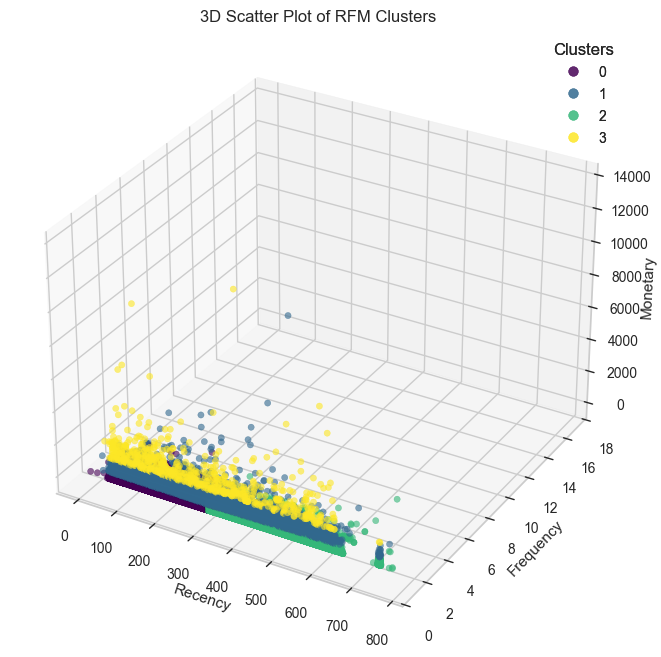

In [88]:
# Prepare the figure and 3D axis
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot
scatter = ax.scatter(
    rfm_df['Recency'],
    rfm_df['Frequency'],
    rfm_df['Monetary'],
    c=rfm_df['cluster'],
    cmap='viridis',
    alpha=0.6
)

# Add labels
ax.set_xlabel('Recency')
ax.set_ylabel('Frequency')
ax.set_zlabel('Monetary')
ax.set_title('3D Scatter Plot of RFM Clusters')

# Add a legend
legend1 = ax.legend(*scatter.legend_elements(), title="Clusters")
ax.add_artist(legend1)

plt.show()


In [85]:
import pandas as pd
import plotly.express as px

# Sample RFM data with clusters for demonstration
# Ensure df_user is the DataFrame containing your RFM data and cluster labels

# Create an interactive 3D scatter plot
fig = px.scatter_3d(
    rfm_df, 
    x='Recency', 
    y='Frequency', 
    z='Monetary', 
    color='cluster',
    labels={'recency': 'Recency', 'frequency': 'Frequency', 'monetary': 'Monetary'},
    title='Interactive 3D Scatter Plot of RFM Clusters',
    opacity=0.7
)

# Customize the layout for better readability
fig.update_layout(
    scene=dict(
        xaxis=dict(title='Recency'),
        yaxis=dict(title='Frequency'),
        zaxis=dict(title='Monetary')
    ),
    margin=dict(l=0, r=0, b=0, t=40)  
)

# Show the plot
fig.show()


## Based on the RFM values of the four identified clusters, the following labels can be assigned to each cluster:

### Cluster 0: "Hibernating Customers"

- **Recency:** 177.6
- **Frequency:** 1.03
- **Monetary:** 121.3
- **Customer Count:** 51,459

**Reason:**

Customers in this cluster have relatively low recency, meaning they haven't made a purchase in a long time. The frequency and monetary values are also relatively low, indicating that they may not be very active in shopping. Based on this information, the customers in this cluster can be considered "Hibernating Customers," or customers who are currently inactive and potentially lost.

### Cluster 1: "Potential Loyalists"

- **Recency:** 279.4
- **Frequency:** 1.13
- **Monetary:** 621.5
- **Customer Count:** 6,096

**Reason:**

Customers in this cluster have moderate recency, with a slightly higher purchase frequency compared to cluster 0. The higher monetary value indicates that they make larger purchases. This suggests potential to become loyal customers if given more attention. Therefore, they can be labeled as "Potential Loyalists."

### Cluster 2: "Lost Customers"

- **Recency:** 438.9
- **Frequency:** 1.02
- **Monetary:** 121.4
- **Customer Count:** 37,821

**Reason:**

This cluster shows very high recency, indicating that these customers haven't made a purchase in a very long time. The low frequency and monetary values suggest that they do not contribute significantly to revenue. They can be considered "Lost Customers" because they are likely no longer interested in your products or services.

### Cluster 3: "Champions"

- **Recency:** 287.9
- **Frequency:** 1.09
- **Monetary:** 1930.8
- **Customer Count:** 719

**Reason:**

This cluster has a very high monetary value compared to the other clusters, indicating that these customers contribute significantly to revenue. Although their recency and frequency are not very high, the amount of money they spend is substantial. They can be labeled as "Champions" because they are the most valuable customers and important to retain.


### Product Analysis

In [103]:
# Gabungkan df dengan rfm_df berdasarkan customer_unique_id
full_merge = pd.merge(df, rfm_df, on='customer_unique_id', how='inner')

# Agregasi untuk menghitung jumlah produk yang terjual di setiap kategori produk untuk setiap segmen
product_analysis = full_merge.groupby(['cluster', 'product_category_name'])['order_id'].count().unstack()
top_products = product_analysis.apply(lambda x: x.nlargest(5).index.tolist(), axis=1)

top_products

cluster
0    [bed_bath_table, health_beauty, sports_leisure...
1    [bed_bath_table, watches_gifts, health_beauty,...
2    [bed_bath_table, furniture_decor, sports_leisu...
3    [computers_accessories, computers, watches_gif...
dtype: object

Top In segmen 0 (Hibernating Customers)

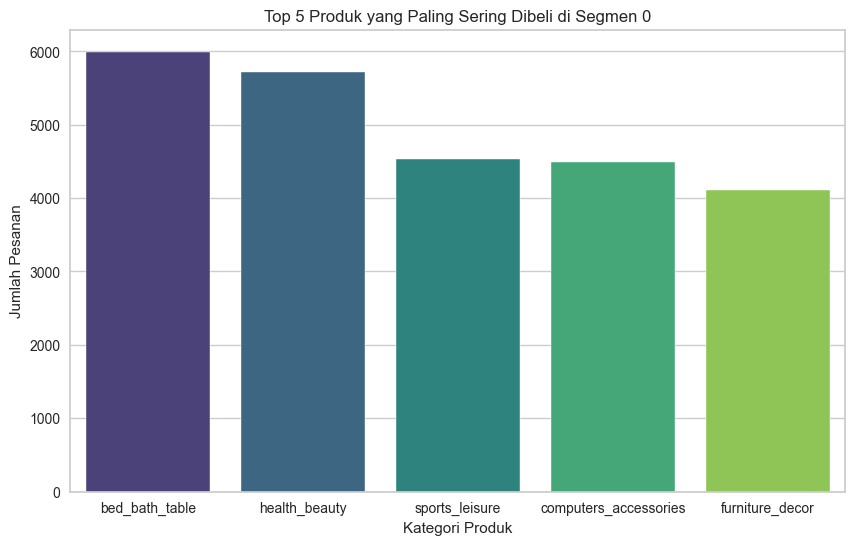

In [104]:
# Data filter for segments 0
top_products_segment_0 = product_analysis.loc[0].nlargest(5)

# Plotting for segments 0
plt.figure(figsize=(10, 6))
sns.barplot(x=top_products_segment_0.index, y=top_products_segment_0.values, palette='viridis')

# Set titles and labels
plt.title('Top 5 Most Purchased Products in Segment 0')
plt.xlabel('Product Categories')
plt.ylabel('Order Quantity')


plt.show()

Top In segmen 1 (Potential Loyalists)

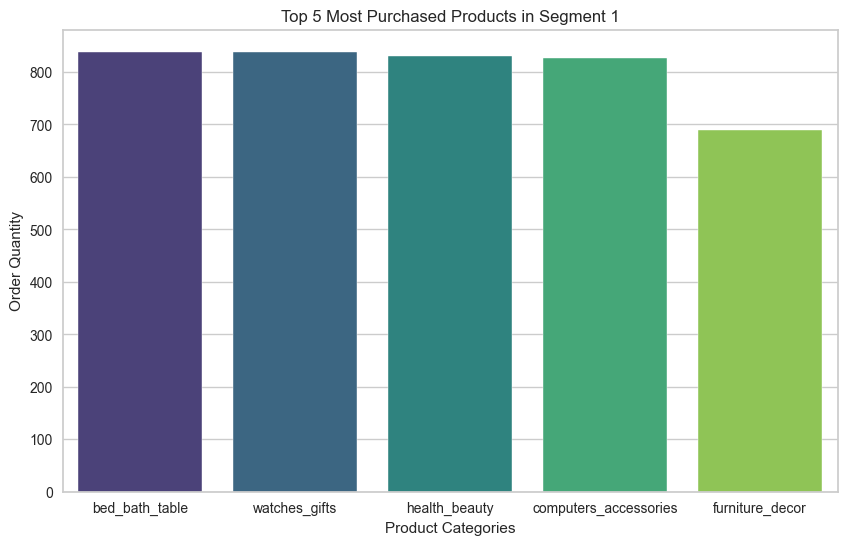

In [108]:

top_products_segment_0 = product_analysis.loc[1].nlargest(5)


plt.figure(figsize=(10, 6))
sns.barplot(x=top_products_segment_0.index, y=top_products_segment_0.values, palette='viridis')


plt.title('Top 5 Most Purchased Products in Segment 1')
plt.xlabel('Product Categories')
plt.ylabel('Order Quantity')


plt.show()

Top In segmen 2 (Lost Customers)

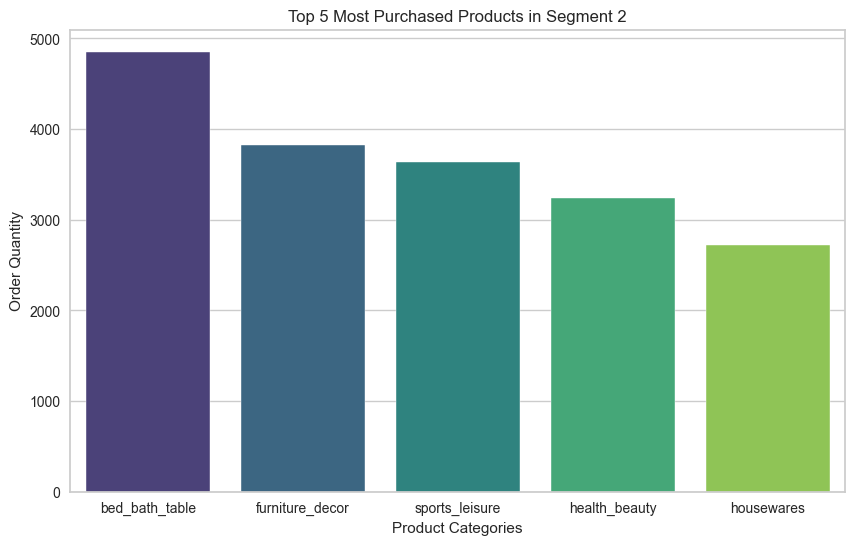

In [109]:

top_products_segment_0 = product_analysis.loc[2].nlargest(5)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_products_segment_0.index, y=top_products_segment_0.values, palette='viridis')


plt.title('Top 5 Most Purchased Products in Segment 2')
plt.xlabel('Product Categories')
plt.ylabel('Order Quantity')


plt.show()

Top In segmen 3 (Champions)

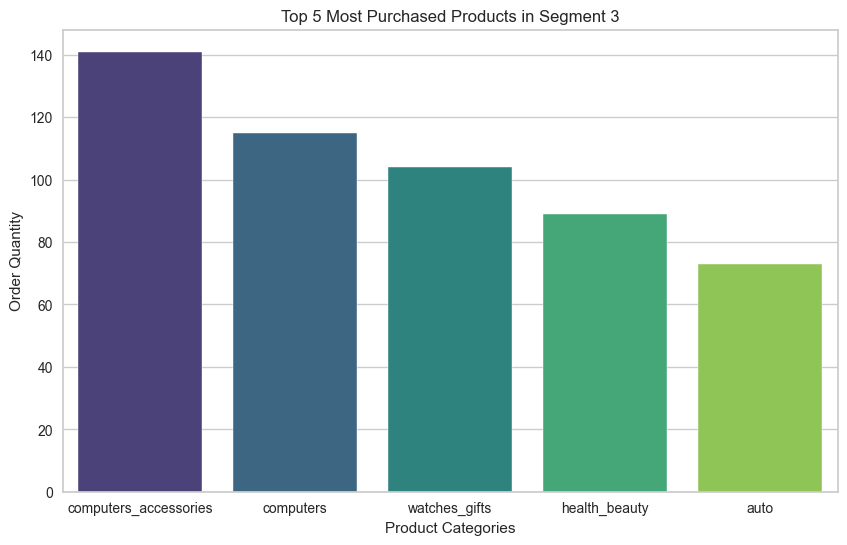

In [110]:

top_products_segment_0 = product_analysis.loc[3].nlargest(5)


plt.figure(figsize=(10, 6))
sns.barplot(x=top_products_segment_0.index, y=top_products_segment_0.values, palette='viridis')


plt.title('Top 5 Most Purchased Products in Segment 3')
plt.xlabel('Product Categories')
plt.ylabel('Order Quantity')


plt.show()

Knowing the most popular products in each segment (cluster) provides useful insights for various business strategies and decisions. By utilizing data on the most popular products in each segment, you can make more informed decisions and more effective strategies to improve customer satisfaction and business results.